# Adversarial robustness training — improved version

**Why the original underperformed:** clean-model test ROC-AUC was 0.497 (chance). The adversarial numbers
were meaningless because ART fine-tuning started from a model that had not learned the task.

**Changes (all in the first 6 code cells; later cells untouched except small bookkeeping patches):**
1. **Face crops** instead of full frames (biggest fix). Haar detector, one stable box per clip, margin 1.3, 256px crops.
2. **More data**: 800 → 2000 videos, and fakes are sampled from *all five* methods (before: only the first method).
3. **Frozen BatchNorm stays in eval mode** (was drifting during Phase 1).
4. **Optimisation**: head LR 3e-4, backbone LR 1e-4, 5 blocks unfrozen, 3+12 epochs, cosine decay, weight decay 1e-2, patience 6.
5. **Checkpoint selection by val ROC-AUC** (F1@0.5 sat at 0.333 and could not rank epochs).
6. **Lighter augmentation** (less extra JPEG, ±5° rotation, no hue shift); sampler off since the data is balanced.
7. **Adversarial fine-tuning**: 0.1× LR, 5 epochs, 0.7/0.3 loss weights, cosine schedule, warning if the clean model is near chance.


In [1]:
# ============================================================
# CELL 1: Configuration
# ============================================================
import os
# Reduce CUDA memory fragmentation (must be set before torch initializes its
# CUDA caching allocator, so this line stays first, before `import torch`).
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

import gc
import json
import random
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch._utils  # noqa: F401
# Kaggle-environment fix (preserved): some torch/torchvision builds don't have
# `torch._utils` bound as an attribute of `torch` yet at this point, which
# makes `from torchvision import transforms` (Cell 2) fail with
# "AttributeError: module 'torch' has no attribute '_utils'". Must run before
# any torchvision import.
import torch.nn as nn
import torch.nn.functional as Fn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from torchvision.utils import make_grid
from torchvision.models import efficientnet_b1, EfficientNet_B1_Weights
import torchvision.transforms.functional as TF

import torch.multiprocessing as _mp
try:
    # Prefer "fork" so DataLoader worker processes inherit this process's
    # already-fixed `torch` module instead of re-importing it from scratch.
    _mp.set_start_method("fork", force=True)
except RuntimeError:
    pass  # start method already set for this kernel session; safe to ignore

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, balanced_accuracy_score, confusion_matrix,
    classification_report, roc_curve,
)
from tqdm import tqdm

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# ============================================================
# CONFIGURATION
# ============================================================
CONFIG = {
    # ---- Data ----
    "data_root": "/kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23",
    "seed": 42,
    "max_videos_to_use": 2000,   # was 800 (only ~560 train videos -> model could not learn). 1000 real + 200 per fake method

    # ---- Temporal sampling ----
    "seq_len": 16,               # kept at 16 -- "16 EVENLY SAMPLED frames" (np.linspace),
                                  # not "16 consecutive frames"
    "frame_pool_size": 32,       # extracted per video so training can vary its 16-frame
                                  # subset epoch to epoch; val/test sampling is deterministic
    "img_size": 224,             # kept at 224 (matches EfficientNet-B1's pretrained pipeline)

    # ---- Face cropping (NEW) ----
    # Deepfake artifacts live on the face. Resizing a full 1080p frame to 224px leaves the
    # face ~40px wide, so the CNN never sees the manipulation. Crops fix this.
    "face_margin": 1.3,
    "face_crop_size": 256,

    # ---- Batching ----
    "batch_size": 8,
    "adv_train_batch_size_fallback": 4,
    "num_workers": 0,   # Kaggle-environment fix (preserved): DataLoader workers on this
                         # image hit torch._utils AttributeError independently; 0 avoids it.

    # ---- Splits ----
    "test_split": 0.15,
    "val_split": 0.15,

    # ---- Social-media DEGRADATION (distinct from augmentation and from adversarial
    # perturbation -- see Cell 2) ----
    "compression_prob": 0.3,   # C23 data is already compressed; less extra degradation
    "compression_downscale_range": (0.7, 1.0),
    "compression_jpeg_quality_range": (30, 70),   # moderate -- NOT the aggressive (10,25)
    "compression_blur_prob": 0.3,
    "compression_blur_kernel": 3,

    # ---- Spatial AUGMENTATION (moderate, preserves forensic artifacts) ----
    "aug_flip_prob": 0.5,               # horizontal only -- never vertical
    "aug_rotation_range": (-5.0, 5.0),
    "aug_brightness_range": (0.9, 1.1),
    "aug_contrast_range": (0.9, 1.1),
    "aug_saturation_range": (0.95, 1.05),
    "aug_hue_range": (0.0, 0.0),   # colour shifts can wash out blending artifacts
    "aug_crop_padding": 4,
    "aug_noise_prob": 0.2,
    "aug_noise_std": 0.01,

    # ---- Model architecture (MAIN model) ----
    # EfficientNet-B1 -> 1280 -> Linear projection -> 512 -> 2-layer UNIDIRECTIONAL LSTM
    # -> mean pooling -> classifier. BiLSTM/attention/GRU/Transformer are NOT used in the
    # main model; attention pooling exists only as an optional Cell 14 ablation comparison.
    "lstm_hidden_size": 512,
    "lstm_num_layers": 2,
    "lstm_bidirectional": False,        # ** main model: unidirectional, per spec **
    "dropout": 0.3,
    "use_temporal_attention": False,    # ** main model: mean pooling, per spec **

    # ---- Staged transfer learning ----
    "phase1_epochs": 3,           # backbone frozen
    "phase2_epochs": 12,          # backbone partially unfrozen, fine-tuned
    "unfreeze_last_n_blocks": 5,
    "backbone_lr": 1e-4,          # EfficientNet-B1 fine-tuning LR
    "head_lr": 3e-4,              # projection/LSTM/classifier LR

    # ---- Optimization ----
    "weight_decay": 1e-2,
    "grad_clip_norm": 5.0,
    "scheduler_factor": 0.5,
    "scheduler_patience": 2,
    "early_stopping_patience": 6,

    # ---- Class imbalance handling ----
    # Train split is roughly 700 real / 3500 fake (~1:5). Using a
    # WeightedRandomSampler (so training batches see much more balanced
    # real/fake exposure) AND aggressive class weighting AT THE SAME TIME is
    # a known way to overcorrect and destabilize training, so this notebook
    # uses ONE primary mechanism by default -- the sampler -- and leaves
    # class weighting off. Cell 14 empirically re-tests this choice against
    # the alternatives (class-weighting only; sampler + mild weighting) using
    # validation macro F1, so the choice is not just asserted.
    "use_weighted_sampler": False,   # data is already balanced 1:1 by construction
    "use_class_weight": False,
    "use_focal_loss": False,
    "focal_gamma": 2.0,

    # ---- Adversarial fine-tuning (Cell 11) ----
    # Per spec: do NOT train an adversarial model from scratch with an
    # aggressive 50/50 loss. Initialize from the best CLEAN checkpoint and
    # fine-tune conservatively.
    "art_finetune_epochs": 5,
    "art_lr_scale": 0.1,                # ART fine-tune LRs = 0.1 x clean-training LRs
    "art_epsilon": 2 / 255,             # conservative starting epsilon
    "art_clean_loss_weight": 0.7,
    "art_adv_loss_weight": 0.3,
    "run_loss_weight_comparison": False,  # optional: also try 0.7/0.3 and 0.5/0.5 (Cell 11)
    "adv_alpha": 1 / 255,                 # PGD step size (evaluation only)

    # ---- FGSM/PGD sanity checks (Cells 9-10) ----
    "sanity_check_epsilons": [0.0, 2 / 255, 4 / 255, 8 / 255],
    "sanity_check_n_samples": 8,

    # ---- Robustness evaluation (Cell 12) ----
    "robustness_fgsm_epsilons": [2 / 255, 4 / 255, 8 / 255],
    "robustness_pgd_configs": [("PGD-3", 3), ("PGD-5", 5)],

    # ---- Threshold selection (validation set ONLY) ----
    "threshold_search_min": 0.30,
    "threshold_search_max": 0.70,
    "threshold_search_step": 0.01,

    # ---- Checkpoints / artifacts ----
    "save_clean_checkpoint": "/kaggle/working/best_clean_model.pth",
    "save_art_checkpoint": "/kaggle/working/best_art_model.pth",
    "save_run_config_path": "/kaggle/working/run_config.json",
    "save_best_metrics_path": "/kaggle/working/best_metrics.json",

    # ---- Ablation study (Cell 14) ----
    # The imbalance-handling ablation (A/B/C) always runs (it's what justifies
    # the sampler default above). The architecture ablations (LSTM layers,
    # pooling, frame count) are individually gated since each trains an
    # additional lightweight model and Kaggle runtime is limited.
    "run_ablation_lstm_layers": False,
    "run_ablation_pooling": False,
    "run_ablation_frames": False,
    "ablation_epochs": 2,

    # ---- System ----
    "device": torch.device("cuda" if torch.cuda.is_available() else "cpu"),
}

USE_AMP = (CONFIG["device"].type == "cuda")


def set_global_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_global_seed(CONFIG["seed"])


# ---- Shared utility functions ----
def free_cuda_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def unnormalize_frame(tensor_frame):
    mean = np.array(IMAGENET_MEAN)
    std = np.array(IMAGENET_STD)
    img = tensor_frame.detach().cpu().numpy().transpose(1, 2, 0)
    return np.clip(std * img + mean, 0, 1)


def compute_metrics(labels, probs, threshold=0.5):
    labels = np.asarray(labels).astype(int)
    probs = np.asarray(probs)
    preds = (probs >= threshold).astype(int)

    try:
        roc_auc = roc_auc_score(labels, probs)
    except ValueError:
        roc_auc = 0.0
    try:
        pr_auc = average_precision_score(labels, probs)
    except ValueError:
        pr_auc = 0.0

    cm = confusion_matrix(labels, preds, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)

    return {
        "threshold": threshold,
        "accuracy": accuracy_score(labels, preds),
        "precision": precision_score(labels, preds, average="macro", zero_division=0),
        "recall": recall_score(labels, preds, average="macro", zero_division=0),
        "f1": f1_score(labels, preds, average="macro", zero_division=0),
        "precision_fake": precision_score(labels, preds, pos_label=1, zero_division=0),
        "recall_fake": recall_score(labels, preds, pos_label=1, zero_division=0),
        "f1_fake": f1_score(labels, preds, pos_label=1, zero_division=0),
        "precision_real": precision_score(labels, preds, pos_label=0, zero_division=0),
        "recall_real": recall_score(labels, preds, pos_label=0, zero_division=0),
        "f1_real": f1_score(labels, preds, pos_label=0, zero_division=0),
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
        "balanced_accuracy": balanced_accuracy_score(labels, preds),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }


def print_metrics(tag, m):
    print(f"[{tag}] thr={m['threshold']:.3f}  Acc={m['accuracy']:.4f}  F1(macro)={m['f1']:.4f}  "
          f"ROC-AUC={m['roc_auc']:.4f}  PR-AUC={m['pr_auc']:.4f}  BalAcc={m['balanced_accuracy']:.4f}  "
          f"| TP={m['tp']} TN={m['tn']} FP={m['fp']} FN={m['fn']}")


print("=" * 70)
print("CONFIGURATION SUMMARY")
print("=" * 70)
print(f"Device                    : {CONFIG['device']}")
print(f"Seed                      : {CONFIG['seed']}")
print(f"seq_len / frame_pool      : {CONFIG['seq_len']} (16 EVENLY SAMPLED frames) / {CONFIG['frame_pool_size']}")
print(f"img_size / batch_size     : {CONFIG['img_size']} / {CONFIG['batch_size']}")
print(f"Phase1/Phase2 epochs      : {CONFIG['phase1_epochs']} / {CONFIG['phase2_epochs']}")
print(f"backbone_lr / head_lr     : {CONFIG['backbone_lr']} / {CONFIG['head_lr']}  weight_decay={CONFIG['weight_decay']}")
print(f"LSTM hidden/layers/bidir  : {CONFIG['lstm_hidden_size']} / {CONFIG['lstm_num_layers']} / "
      f"{CONFIG['lstm_bidirectional']}  (main model: UNIDIRECTIONAL)")
print(f"Temporal pooling (main)   : {'attention' if CONFIG['use_temporal_attention'] else 'mean'}")
print(f"Imbalance handling (main) : sampler={CONFIG['use_weighted_sampler']}  class_weight={CONFIG['use_class_weight']}")
print(f"ART fine-tune epsilon/w   : {CONFIG['art_epsilon']:.4f} / clean={CONFIG['art_clean_loss_weight']} "
      f"adv={CONFIG['art_adv_loss_weight']}")
print("=" * 70)
print("NOTE on reproducibility: cuDNN's fused RNN (LSTM) backward kernel is not bit-exact")
print("deterministic even with cudnn.deterministic=True (a known PyTorch/cuDNN limitation).")


CONFIGURATION SUMMARY
Device                    : cuda
Seed                      : 42
seq_len / frame_pool      : 16 (16 EVENLY SAMPLED frames) / 32
img_size / batch_size     : 224 / 8
Phase1/Phase2 epochs      : 3 / 12
backbone_lr / head_lr     : 0.0001 / 0.0003  weight_decay=0.01
LSTM hidden/layers/bidir  : 512 / 2 / False  (main model: UNIDIRECTIONAL)
Temporal pooling (main)   : mean
Imbalance handling (main) : sampler=False  class_weight=False
ART fine-tune epsilon/w   : 0.0078 / clean=0.7 adv=0.3
NOTE on reproducibility: cuDNN's fused RNN (LSTM) backward kernel is not bit-exact
deterministic even with cudnn.deterministic=True (a known PyTorch/cuDNN limitation).


In [2]:
# ============================================================
# CELL 2: Dataset and preprocessing (UPDATED FOR PERFORMANCE)
# ============================================================

# --- SAFETY OVERRIDE FOR KAGGLE RUNTIME ---
# Cap the dataset size so it doesn't try to extract 5,000+ videos for 4 hours.
# Overriding the CONFIG here so you don't have to change Cell 1.
if CONFIG.get("max_videos_to_use") is None:
    CONFIG["max_videos_to_use"] = 800  
CONFIG["num_workers"] = 2  # Enabling parallel data loading

def discover_videos(data_root, max_videos=None):
    root_path = Path(data_root)
    real_folders = ["original", "Original", "real"]
    fake_folders = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures", "FaceShifter"]
    rng = random.Random(CONFIG["seed"])

    real_videos = []
    for rf in real_folders:
        r_path = root_path / rf
        if r_path.exists():
            real_videos.extend(sorted(list(r_path.glob("*.mp4")) + list(r_path.glob("*/*.mp4"))))

    # FIX: the old code concatenated all fake folders and kept the first N, i.e. ONLY
    # the first manipulation method. Now fakes are sampled evenly from EVERY method.
    fake_by_method = {}
    for ff in fake_folders:
        f_path = root_path / ff
        if f_path.exists():
            vids = sorted(list(f_path.glob("*.mp4")) + list(f_path.glob("*/*.mp4")))
            if vids:
                fake_by_method[ff] = vids

    rng.shuffle(real_videos)
    fake_videos = []
    if max_videos is not None:
        half_limit = max_videos // 2
        real_videos = real_videos[:half_limit]
        per_method = max(1, half_limit // max(len(fake_by_method), 1))
        for name, vids in fake_by_method.items():
            vids = list(vids); rng.shuffle(vids)
            fake_videos.extend(vids[:per_method])
    else:
        for vids in fake_by_method.values():
            fake_videos.extend(vids)

    print(f"Discovered {len(real_videos)} real videos and {len(fake_videos)} fake videos "
          f"({', '.join(f'{k}' for k in fake_by_method)}) under {data_root}")
    return real_videos, fake_videos


# ---------------- Face detection / cropping (NEW) ----------------
_FACE_CASCADE = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")


def _detect_face_box(frame_bgr):
    h, w = frame_bgr.shape[:2]
    scale = 640.0 / max(h, w) if max(h, w) > 640 else 1.0
    small = cv2.resize(frame_bgr, None, fx=scale, fy=scale) if scale < 1.0 else frame_bgr
    gray = cv2.cvtColor(small, cv2.COLOR_BGR2GRAY)
    faces = _FACE_CASCADE.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(40, 40))
    if len(faces) == 0:
        return None
    x, y, fw, fh = max(faces, key=lambda b: b[2] * b[3])
    return x / scale, y / scale, fw / scale, fh / scale


def _video_face_square(frames_bgr, margin):
    """One stable square crop for the whole clip (median face centre, largest face size)
    -- stable boxes avoid frame-to-frame jitter that would look like a temporal artifact.
    Returns (x0, y0, x1, y1, detected_flag)."""
    h, w = frames_bgr[0].shape[:2]
    boxes = [bx for bx in (_detect_face_box(f) for f in frames_bgr[::4]) if bx is not None]
    if boxes:
        cx = float(np.median([x + fw / 2 for x, y, fw, fh in boxes]))
        cy = float(np.median([y + fh / 2 for x, y, fw, fh in boxes]))
        size = max(max(fw, fh) for x, y, fw, fh in boxes) * margin
        detected = True
    else:                                   # fallback: central square
        cx, cy, size, detected = w / 2, h / 2, 0.7 * min(h, w), False
    size = min(size, h, w)
    x0 = int(np.clip(cx - size / 2, 0, w - size)); y0 = int(np.clip(cy - size / 2, 0, h - size))
    return x0, y0, int(x0 + size), int(y0 + size), detected


def extract_videos_to_disk(data_root, output_dir="/kaggle/working/face_frames",
                            max_videos=None, frame_pool_size=32):
    out_path = Path(output_dir)
    out_path.mkdir(parents=True, exist_ok=True)

    real_videos, fake_videos = discover_videos(data_root, max_videos)
    records = []
    all_tasks = [(p, 0) for p in real_videos] + [(p, 1) for p in fake_videos]
    n_fallback = 0

    print(f"Pre-extracting {len(all_tasks)} videos to disk as FACE CROPS "
          f"({frame_pool_size} frames/video; this runs only once)...")

    for v_path_str, label in tqdm(all_tasks, desc="Extracting Faces"):
        v_path = Path(v_path_str)
        # include the method folder in the name: fake file names are unique only within a method
        tag = v_path.parent.name
        vid_out_dir = out_path / ("real" if label == 0 else "fake") / f"{tag}__{v_path.stem}"
        vid_out_dir.mkdir(parents=True, exist_ok=True)

        existing_frames = list(vid_out_dir.glob("*.jpg"))
        if len(existing_frames) >= min(frame_pool_size, CONFIG["seq_len"]):
            records.append((str(vid_out_dir), label))
            continue

        cap = cv2.VideoCapture(str(v_path))
        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        if total_frames >= frame_pool_size:
            indices = np.linspace(0, total_frames - 1, frame_pool_size, dtype=int)
        else:
            indices = np.arange(max(total_frames, 1))
        target_indices = set(int(i) for i in indices)

        frames, curr_frame = [], 0
        while cap.isOpened() and len(frames) < len(target_indices):
            ret, frame = cap.read()
            if not ret:
                break
            if curr_frame in target_indices:
                frames.append(frame)
            curr_frame += 1
        cap.release()

        if frames:
            x0, y0, x1, y1, ok = _video_face_square(frames, CONFIG["face_margin"])
            n_fallback += (not ok)
            cs = CONFIG["face_crop_size"]
            for k, fr in enumerate(frames):
                crop = cv2.resize(fr[y0:y1, x0:x1], (cs, cs), interpolation=cv2.INTER_AREA)
                cv2.imwrite(str(vid_out_dir / f"frame_{k:03d}.jpg"), crop,
                            [int(cv2.IMWRITE_JPEG_QUALITY), 95])
            records.append((str(vid_out_dir), label))

    print(f"Face detector fell back to a centre crop for {n_fallback}/{len(all_tasks)} new videos.")
    return records


extracted_records = extract_videos_to_disk(
    CONFIG["data_root"],
    output_dir="/kaggle/working/face_frames",     # NEW dir so old full-frame cache is not reused
    max_videos=CONFIG["max_videos_to_use"],
    frame_pool_size=CONFIG["frame_pool_size"],
)

if len(extracted_records) == 0:
    raise ValueError("No frames were extracted. Check your CONFIG['data_root'] path.")

n_real = sum(1 for _, l in extracted_records if l == 0)
n_fake = sum(1 for _, l in extracted_records if l == 1)
print(f"Extraction complete. Total usable videos: {len(extracted_records)} "
      f"(real={n_real}, fake={n_fake})")


def get_group_id(record):
    return Path(record[0]).name.split('__')[-1].split('_')[0]


groups = [get_group_id(r) for r in extracted_records]
labels_all = [r[1] for r in extracted_records]

# ---- Split off TEST first ----
gss_test = GroupShuffleSplit(n_splits=1, test_size=CONFIG["test_split"], random_state=CONFIG["seed"])
train_val_idx, test_idx = next(gss_test.split(extracted_records, labels_all, groups=groups))

train_val_records = [extracted_records[i] for i in train_val_idx]
test_records_raw = [extracted_records[i] for i in test_idx]
train_val_groups = [groups[i] for i in train_val_idx]
train_val_labels = [labels_all[i] for i in train_val_idx]

# ---- Split remaining into TRAIN / VAL ----
val_ratio_adjusted = CONFIG["val_split"] / (1.0 - CONFIG["test_split"])
gss_val = GroupShuffleSplit(n_splits=1, test_size=val_ratio_adjusted, random_state=CONFIG["seed"])
train_idx, val_idx = next(gss_val.split(train_val_records, train_val_labels, groups=train_val_groups))

train_records = [train_val_records[i] for i in train_idx]
val_records_raw = [train_val_records[i] for i in val_idx]
train_groups = [train_val_groups[i] for i in train_idx]
val_groups_raw = [train_val_groups[i] for i in val_idx]
test_groups_raw = [groups[i] for i in test_idx]


def balance_split(records, seed):
    real = [r for r in records if r[1] == 0]
    fake = [r for r in records if r[1] == 1]
    n = min(len(real), len(fake))
    rng = random.Random(seed)
    rng.shuffle(real)
    rng.shuffle(fake)
    balanced = real[:n] + fake[:n]
    rng.shuffle(balanced)
    return balanced


val_records = balance_split(val_records_raw, CONFIG["seed"])
test_records = balance_split(test_records_raw, CONFIG["seed"])

val_groups = [get_group_id(r) for r in val_records]
test_groups = [get_group_id(r) for r in test_records]


def split_report(name, records, grps):
    n_real = sum(1 for _, l in records if l == 0)
    n_fake = sum(1 for _, l in records if l == 1)
    print(f"{name:<6}: {len(records):5d} videos  |  real={n_real:5d}  fake={n_fake:5d}  "
          f"|  unique groups={len(set(grps)):5d}")


print("=" * 60)
print("GROUP-AWARE SPLIT REPORT")
print("=" * 60)
split_report("Train", train_records, train_groups)
split_report("Val", val_records, val_groups)
split_report("Test", test_records, test_groups)

train_group_set = set(train_groups)
val_group_set = set(val_groups_raw)
test_group_set = set(test_groups_raw)

overlap_train_val = train_group_set & val_group_set
overlap_train_test = train_group_set & test_group_set
overlap_val_test = val_group_set & test_group_set

assert not overlap_train_val, f"Group leakage between train/val: {overlap_train_val}"
assert not overlap_train_test, f"Group leakage between train/test: {overlap_train_test}"
assert not overlap_val_test, f"Group leakage between val/test: {overlap_val_test}"

print("\nGroup-overlap check: PASSED -- no source-identity group appears in more than one split.")
print("=" * 60)


def apply_social_media_compression(img_rgb, scale_factor, should_blur, quality):
    h, w, _ = img_rgb.shape
    new_h, new_w = max(1, int(h * scale_factor)), max(1, int(w * scale_factor))
    img_resized = cv2.resize(img_rgb, (new_w, new_h), interpolation=cv2.INTER_AREA)
    img_resized = cv2.resize(img_resized, (w, h), interpolation=cv2.INTER_LINEAR)

    if should_blur:
        k = CONFIG["compression_blur_kernel"]
        k = k if k % 2 == 1 else k + 1
        img_resized = cv2.GaussianBlur(img_resized, (k, k), 0)

    encode_param = [int(cv2.IMWRITE_JPEG_QUALITY), quality]
    _, encimg = cv2.imencode('.jpg', img_resized, encode_param)
    decimg = cv2.imdecode(encimg, 1)
    return decimg


class PreextractedVideoDataset(Dataset):
    def __init__(self, sample_records, seq_len=16, img_size=224, is_train=True):
        self.sample_records = sample_records
        self.seq_len = seq_len
        self.img_size = img_size
        self.is_train = is_train

    def __len__(self):
        return len(self.sample_records)

    def _sample_frame_indices(self, n_available, rng):
        if n_available <= self.seq_len:
            return list(range(n_available))

        bounds = np.linspace(0, n_available, self.seq_len + 1).astype(int)
        indices = []
        for i in range(self.seq_len):
            lo, hi = int(bounds[i]), int(bounds[i + 1])
            hi = max(hi, lo + 1)
            if self.is_train:
                indices.append(rng.randint(lo, hi - 1))
            else:
                indices.append((lo + hi - 1) // 2)
        return indices

    def __getitem__(self, idx):
        folder_path, label = self.sample_records[idx]
        folder = Path(folder_path)
        frame_files = sorted(list(folder.glob("*.jpg")))
        n_available = len(frame_files)

        rng = random.Random() if self.is_train else random.Random(0)

        frame_indices = self._sample_frame_indices(n_available, rng)
        selected_files = [frame_files[i] for i in frame_indices]

        should_compress = self.is_train and rng.random() < CONFIG["compression_prob"]
        compress_quality = (rng.randint(*CONFIG["compression_jpeg_quality_range"])
                             if should_compress else None)
        should_blur = should_compress and rng.random() < CONFIG["compression_blur_prob"]
        scale_factor = rng.uniform(*CONFIG["compression_downscale_range"])

        if self.is_train:
            do_flip = rng.random() < CONFIG["aug_flip_prob"]
            rotation_angle = rng.uniform(*CONFIG["aug_rotation_range"])
            brightness_factor = rng.uniform(*CONFIG["aug_brightness_range"])
            contrast_factor = rng.uniform(*CONFIG["aug_contrast_range"])
            saturation_factor = rng.uniform(*CONFIG["aug_saturation_range"])
            hue_factor = rng.uniform(*CONFIG["aug_hue_range"])
            crop_padding = CONFIG["aug_crop_padding"]
            crop_top = rng.randint(0, 2 * crop_padding)
            crop_left = rng.randint(0, 2 * crop_padding)
            add_noise = rng.random() < CONFIG["aug_noise_prob"]

        processed_frames = []
        for f_path in selected_files:
            img = cv2.imread(str(f_path))
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

            if should_compress:
                img_rgb = apply_social_media_compression(
                    img_rgb, scale_factor, should_blur, compress_quality
                )

            pil_img = transforms.ToPILImage()(img_rgb)
            pil_img = TF.resize(pil_img, (self.img_size, self.img_size))

            if self.is_train:
                pil_img = TF.rotate(pil_img, rotation_angle)
                pil_img = TF.pad(pil_img, padding=crop_padding, padding_mode='reflect')
                pil_img = TF.crop(pil_img, top=crop_top, left=crop_left,
                                   height=self.img_size, width=self.img_size)
                if do_flip:
                    pil_img = TF.hflip(pil_img)
                pil_img = TF.adjust_brightness(pil_img, brightness_factor)
                pil_img = TF.adjust_contrast(pil_img, contrast_factor)
                pil_img = TF.adjust_hue(pil_img, hue_factor)
                pil_img = TF.adjust_saturation(pil_img, saturation_factor)

            tensor_frame = TF.to_tensor(pil_img)
            tensor_frame = TF.normalize(tensor_frame, mean=IMAGENET_MEAN, std=IMAGENET_STD)

            if self.is_train and add_noise:
                tensor_frame = tensor_frame + torch.randn_like(tensor_frame) * CONFIG["aug_noise_std"]

            processed_frames.append(tensor_frame)

        while len(processed_frames) < self.seq_len:
            if len(processed_frames) > 0:
                processed_frames.append(processed_frames[-1].clone())
            else:
                processed_frames.append(torch.zeros(3, self.img_size, self.img_size))

        video_tensor = torch.stack(processed_frames[:self.seq_len])
        label_tensor = torch.tensor(label, dtype=torch.float32)
        return video_tensor, label_tensor


# ---- Datasets ----
train_dataset = PreextractedVideoDataset(train_records, seq_len=CONFIG["seq_len"],
                                          img_size=CONFIG["img_size"], is_train=True)
val_dataset = PreextractedVideoDataset(val_records, seq_len=CONFIG["seq_len"],
                                        img_size=CONFIG["img_size"], is_train=False)
test_dataset = PreextractedVideoDataset(test_records, seq_len=CONFIG["seq_len"],
                                         img_size=CONFIG["img_size"], is_train=False)

# ---- Class imbalance handling: WeightedRandomSampler for TRAINING only ----
train_labels_for_sampler = np.array([r[1] for r in train_records])
class_counts = np.bincount(train_labels_for_sampler, minlength=2)
print(f"Train class counts -> real={class_counts[0]}, fake={class_counts[1]} "
      f"(ratio 1:{class_counts[1] / max(class_counts[0], 1):.2f})")

class_weights_for_sampler = 1.0 / np.maximum(class_counts, 1)
sample_weights = class_weights_for_sampler[train_labels_for_sampler]

# --- DATALOADER WORKER INITIALIZATION FIX ---
def worker_init_fn(worker_id):
    """Ensures torch._utils is loaded in worker threads before torchvision attempts to use it."""
    import torch
    import torch._utils

if CONFIG["use_weighted_sampler"]:
    train_sampler = WeightedRandomSampler(
        weights=torch.as_tensor(sample_weights, dtype=torch.double),
        num_samples=len(sample_weights),
        replacement=True,
    )
    train_loader = DataLoader(
        train_dataset, 
        batch_size=CONFIG["batch_size"],
        sampler=train_sampler, 
        num_workers=CONFIG["num_workers"],
        worker_init_fn=worker_init_fn,
        drop_last=True, 
        pin_memory=True
    )
    print("WeightedRandomSampler ENABLED for the training DataLoader.")
else:
    train_loader = DataLoader(
        train_dataset, 
        batch_size=CONFIG["batch_size"], 
        shuffle=True,
        num_workers=CONFIG["num_workers"], 
        worker_init_fn=worker_init_fn,
        drop_last=True, 
        pin_memory=True
    )
    print("WeightedRandomSampler DISABLED -- using plain shuffled sampling.")

val_loader = DataLoader(
    val_dataset, 
    batch_size=CONFIG["batch_size"], 
    shuffle=False,
    num_workers=CONFIG["num_workers"], 
    worker_init_fn=worker_init_fn,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset, 
    batch_size=CONFIG["batch_size"], 
    shuffle=False,
    num_workers=CONFIG["num_workers"],
    worker_init_fn=worker_init_fn,
    pin_memory=True
)

print(f"\nSetup complete! Train batches: {len(train_loader)} | "
      f"Val batches: {len(val_loader)} | Test batches: {len(test_loader)}")

print("\nActive augmentation configuration:")
for k in ["compression_prob", "compression_downscale_range", "compression_jpeg_quality_range",
          "compression_blur_prob", "aug_flip_prob", "aug_rotation_range", "aug_brightness_range",
          "aug_contrast_range", "aug_saturation_range", "aug_hue_range",
          "aug_noise_prob", "aug_noise_std"]:
    print(f"  {k}: {CONFIG[k]}")

Discovered 1000 real videos and 1000 fake videos (Deepfakes, Face2Face, FaceSwap, NeuralTextures, FaceShifter) under /kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23
Pre-extracting 2000 videos to disk as FACE CROPS (32 frames/video; this runs only once)...


Extracting Faces: 100%|██████████| 2000/2000 [1:22:54<00:00,  2.49s/it]

Face detector fell back to a centre crop for 0/2000 new videos.
Extraction complete. Total usable videos: 2000 (real=1000, fake=1000)
GROUP-AWARE SPLIT REPORT
Train :  1386 videos  |  real=  700  fake=  686  |  unique groups=  700
Val   :   300 videos  |  real=  150  fake=  150  |  unique groups=  150
Test  :   300 videos  |  real=  150  fake=  150  |  unique groups=  150

Group-overlap check: PASSED -- no source-identity group appears in more than one split.
Train class counts -> real=700, fake=686 (ratio 1:0.98)
WeightedRandomSampler DISABLED -- using plain shuffled sampling.

Setup complete! Train batches: 173 | Val batches: 38 | Test batches: 38

Active augmentation configuration:
  compression_prob: 0.3
  compression_downscale_range: (0.7, 1.0)
  compression_jpeg_quality_range: (30, 70)
  compression_blur_prob: 0.3
  aug_flip_prob: 0.5
  aug_rotation_range: (-5.0, 5.0)
  aug_brightness_range: (0.9, 1.1)
  aug_contrast_range: (0.9, 1.1)
  aug_saturation_range: (0.95, 1.05)
  aug_hu

Class distribution per split:
Split  Real  Fake
Train   700   686
  Val   150   150
 Test   150   150


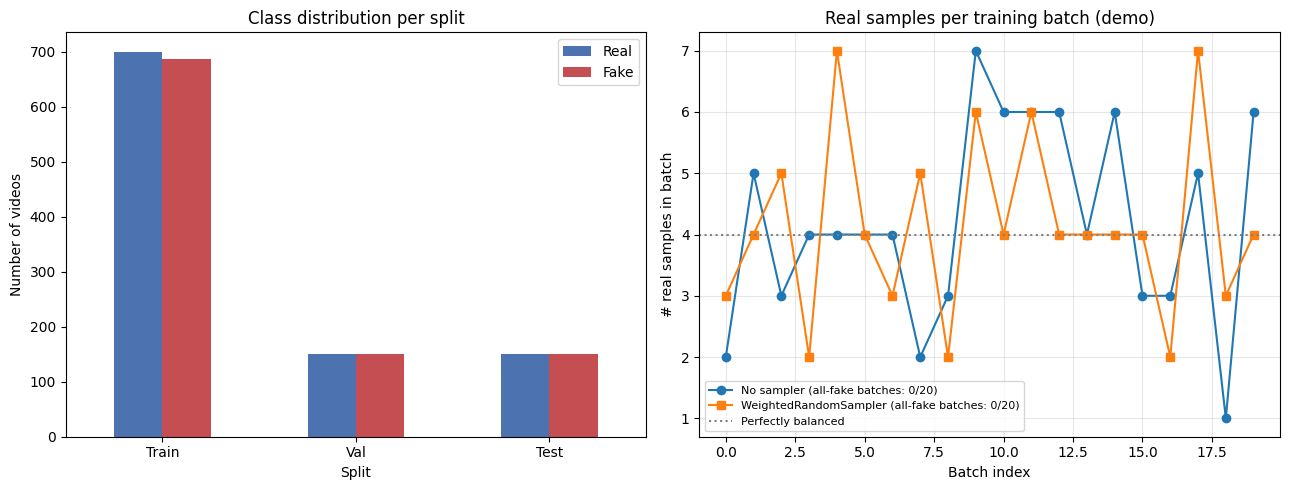


Out of 20 demo batches: 0 were all-fake WITHOUT the sampler, vs 0 WITH the WeightedRandomSampler (sampler DISABLED for actual training).


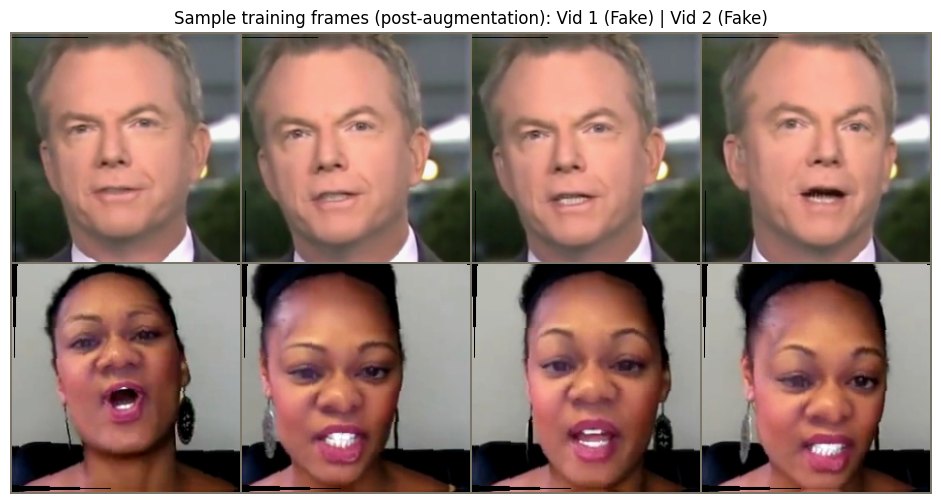

In [3]:
# ============================================================
# CELL 3: Data distribution analysis
# ============================================================
# Visualizes the class imbalance and demonstrates, concretely, the
# all-fake-batch problem described in the brief -- with and without the
# WeightedRandomSampler -- plus a quick look at sample training frames.

split_counts = pd.DataFrame([
    {"Split": "Train", "Real": sum(1 for _, l in train_records if l == 0),
     "Fake": sum(1 for _, l in train_records if l == 1)},
    {"Split": "Val", "Real": sum(1 for _, l in val_records if l == 0),
     "Fake": sum(1 for _, l in val_records if l == 1)},
    {"Split": "Test", "Real": sum(1 for _, l in test_records if l == 0),
     "Fake": sum(1 for _, l in test_records if l == 1)},
])
print("Class distribution per split:")
print(split_counts.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

split_counts.set_index("Split")[["Real", "Fake"]].plot(kind="bar", ax=axes[0], color=["#4C72B0", "#C44E52"])
axes[0].set_title("Class distribution per split")
axes[0].set_ylabel("Number of videos")
axes[0].tick_params(axis="x", rotation=0)

# ---- Demonstrate the all-fake-batch problem, with vs without the sampler ----
plain_loader_demo = DataLoader(train_dataset, batch_size=CONFIG["batch_size"], shuffle=True,
                                num_workers=0, drop_last=True)
n_demo_batches = 20

def batch_real_counts(loader, n_batches):
    counts = []
    it = iter(loader)
    for _ in range(n_batches):
        _, labels = next(it)
        counts.append(int((labels == 0).sum().item()))
    return counts

plain_real_counts = batch_real_counts(plain_loader_demo, n_demo_batches)
sampler_real_counts = batch_real_counts(train_loader, n_demo_batches)

n_allfake_plain = sum(1 for c in plain_real_counts if c == 0)
n_allfake_sampler = sum(1 for c in sampler_real_counts if c == 0)

axes[1].plot(range(n_demo_batches), plain_real_counts, marker="o",
             label=f"No sampler (all-fake batches: {n_allfake_plain}/{n_demo_batches})")
axes[1].plot(range(n_demo_batches), sampler_real_counts, marker="s",
             label=f"WeightedRandomSampler (all-fake batches: {n_allfake_sampler}/{n_demo_batches})")
axes[1].axhline(CONFIG["batch_size"] / 2, color="gray", linestyle=":", label="Perfectly balanced")
axes[1].set_title("Real samples per training batch (demo)")
axes[1].set_xlabel("Batch index")
axes[1].set_ylabel("# real samples in batch")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("/kaggle/working/class_distribution_and_sampler_demo.png", dpi=150)
plt.show()

print(f"\nOut of {n_demo_batches} demo batches: "
      f"{n_allfake_plain} were all-fake WITHOUT the sampler, vs "
      f"{n_allfake_sampler} WITH the WeightedRandomSampler "
      f"(sampler {'ENABLED' if CONFIG['use_weighted_sampler'] else 'DISABLED'} for actual training).")

del plain_loader_demo
free_cuda_memory()

# ---- Sample training frames (post-augmentation) ----
images, labels = next(iter(train_loader))
video_1_frames = images[0, :4]
video_2_frames = images[1, :4]
images_to_show = torch.cat([video_1_frames, video_2_frames], dim=0)
grid = make_grid(images_to_show, nrow=4)

mean_t = torch.tensor(IMAGENET_MEAN, device=grid.device).view(3, 1, 1)
std_t = torch.tensor(IMAGENET_STD, device=grid.device).view(3, 1, 1)
grid_unnorm = torch.clamp(grid * std_t + mean_t, 0.0, 1.0)

label_mapping = {0: "Real", 1: "Fake"}
titles = f"Vid 1 ({label_mapping[int(labels[0].item())]}) | Vid 2 ({label_mapping[int(labels[1].item())]})"

plt.figure(figsize=(12, 6))
plt.imshow(grid_unnorm.permute(1, 2, 0).cpu().numpy())
plt.title(f"Sample training frames (post-augmentation): {titles}")
plt.axis("off")
plt.show()


In [4]:
# ============================================================
# CELL 4: Model architecture
# ============================================================
# MAIN model (per the architecture constraint): EfficientNet-B1 (pretrained,
# frame-level feature extractor) -> 1280 -> Linear projection -> 512 ->
# 2-layer UNIDIRECTIONAL LSTM (hidden=512) -> MEAN pooling over timesteps ->
# classifier -> 1 logit. BiLSTM/GRU/Transformer are NOT used here. An
# optional attention-pooling path exists (`use_attention=True`) purely for
# the Cell 14 ablation comparison -- it is NOT enabled by default.

class TemporalAttentionPooling(nn.Module):
    """Optional (ablation-only) alternative to mean pooling."""
    def __init__(self, input_dim):
        super().__init__()
        self.attn = nn.Sequential(
            nn.Linear(input_dim, input_dim // 2),
            nn.Tanh(),
            nn.Linear(input_dim // 2, 1),
        )

    def forward(self, x):
        scores = self.attn(x)
        weights = torch.softmax(scores, dim=1)
        pooled = torch.sum(weights * x, dim=1)
        return pooled, weights.squeeze(-1)


class FFPPDeepfakeDetectorV2(nn.Module):
    def __init__(self, lstm_hidden_size=None, num_layers=None, bidirectional=None,
                 dropout=None, use_attention=None):
        super().__init__()
        lstm_hidden_size = lstm_hidden_size or CONFIG["lstm_hidden_size"]
        num_layers = num_layers or CONFIG["lstm_num_layers"]
        bidirectional = CONFIG["lstm_bidirectional"] if bidirectional is None else bidirectional
        dropout = CONFIG["dropout"] if dropout is None else dropout
        use_attention = CONFIG["use_temporal_attention"] if use_attention is None else use_attention

        # ---- EfficientNet-B1 spatial feature extractor (pretrained, unchanged) ----
        weights = EfficientNet_B1_Weights.DEFAULT
        base_model = efficientnet_b1(weights=weights)
        self.feature_extractor = nn.Sequential(*list(base_model.children())[:-1])  # [stages, avgpool]
        self.feature_dim = 1280
        self.dropout_cnn = nn.Dropout(p=dropout)
        self.flatten = nn.Flatten()

        # ---- Projection: 1280 -> 512 ----
        self.projection = nn.Sequential(
            nn.Linear(self.feature_dim, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout),
        )

        # ---- Temporal model: 2-layer UNIDIRECTIONAL LSTM by default ----
        self.bidirectional = bidirectional
        self.use_attention = use_attention
        self.lstm = nn.LSTM(
            input_size=512,
            hidden_size=lstm_hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=bidirectional,
            dropout=(dropout if num_layers > 1 else 0.0),
        )
        lstm_out_dim = lstm_hidden_size * (2 if bidirectional else 1)

        self.temporal_pool = TemporalAttentionPooling(lstm_out_dim) if use_attention else None

        # ---- Classification head ----
        self.classifier = nn.Sequential(
            nn.Linear(lstm_out_dim, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout),
            nn.Linear(256, 1),
        )

        self.last_attention_weights = None

    def forward(self, x, verbose_shape_check=False):
        batch_size, seq_len, c, h, w = x.shape
        assert (c, h, w) == (3, CONFIG["img_size"], CONFIG["img_size"]), (
            f"Expected input channels/H/W = (3,{CONFIG['img_size']},{CONFIG['img_size']}), got {(c, h, w)}"
        )
        if verbose_shape_check:
            print(f"  Input                    : {tuple(x.shape)}")

        x = x.view(batch_size * seq_len, c, h, w)
        if verbose_shape_check:
            print(f"  Reshaped for CNN         : {tuple(x.shape)}")

        features = self.feature_extractor(x)
        features = self.flatten(features)
        if verbose_shape_check:
            print(f"  EfficientNet-B1 output   : {tuple(features.shape)}")
        assert features.shape[1] == self.feature_dim, (
            f"Expected {self.feature_dim}-D EfficientNet-B1 features, got {features.shape[1]}"
        )

        features = self.dropout_cnn(features)
        features = self.projection(features)
        if verbose_shape_check:
            print(f"  After projection (->512) : {tuple(features.shape)}")
        assert features.shape[1] == 512, f"Expected 512-D projected features, got {features.shape[1]}"

        features = features.view(batch_size, seq_len, -1)
        if verbose_shape_check:
            print(f"  Reshaped for LSTM        : {tuple(features.shape)}")

        lstm_out, _ = self.lstm(features)
        if verbose_shape_check:
            print(f"  LSTM output              : {tuple(lstm_out.shape)}")

        if self.use_attention:
            pooled, attn_weights = self.temporal_pool(lstm_out)
            self.last_attention_weights = attn_weights.detach()
        else:
            pooled = torch.mean(lstm_out, dim=1)
            self.last_attention_weights = None
        if verbose_shape_check:
            print(f"  Pooled ({'attention' if self.use_attention else 'mean':<9}) : {tuple(pooled.shape)}")

        out = self.classifier(pooled)
        if verbose_shape_check:
            print(f"  Classifier output        : {tuple(out.shape)}")

        out = out.squeeze(1)
        if verbose_shape_check:
            print(f"  Final logits (per video) : {tuple(out.shape)}")
        return out

    def train(self, mode=True):
        """FIX: model.train() used to put the FROZEN backbone's BatchNorm layers in train
        mode, so their running stats drifted every batch while their weights stayed frozen.
        BN layers with no trainable params are now kept in eval mode."""
        super().train(mode)
        if mode:
            for m in self.feature_extractor.modules():
                if isinstance(m, nn.modules.batchnorm._BatchNorm) and \
                        not any(p.requires_grad for p in m.parameters()):
                    m.eval()
        return self

    # ---- Staged transfer-learning helpers ----
    def freeze_backbone(self):
        for p in self.feature_extractor.parameters():
            p.requires_grad = False

    def unfreeze_last_n_blocks(self, n):
        backbone_blocks = list(self.feature_extractor[0].children())
        for block in backbone_blocks[-n:]:
            for p in block.parameters():
                p.requires_grad = True

    def backbone_param_groups(self, backbone_lr, head_lr):
        backbone_params = [p for p in self.feature_extractor.parameters() if p.requires_grad]
        head_params = (
            list(self.projection.parameters())
            + list(self.lstm.parameters())
            + (list(self.temporal_pool.parameters()) if self.use_attention else [])
            + list(self.classifier.parameters())
        )
        groups = [{"params": head_params, "lr": head_lr}]
        if backbone_params:
            groups.append({"params": backbone_params, "lr": backbone_lr})
        return groups


def build_model(**overrides):
    m = FFPPDeepfakeDetectorV2(**overrides).to(CONFIG["device"])
    m.freeze_backbone()  # Phase 1 always starts with the backbone frozen
    return m


model = build_model()
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("Model initialized:")
print(f"  EfficientNet-B1 -> projection(1280->512) -> "
      f"{'Bi' if CONFIG['lstm_bidirectional'] else ''}LSTM(hidden={CONFIG['lstm_hidden_size']}, "
      f"layers={CONFIG['lstm_num_layers']}, bidirectional={CONFIG['lstm_bidirectional']}) -> "
      f"{'attention' if CONFIG['use_temporal_attention'] else 'mean'} pooling -> classifier(256) -> 1 logit")
print(f"  Total params: {total_params:,} | Trainable (Phase 1, backbone frozen): {trainable_params:,}")

print("\nShape verification (dummy forward pass, batch_size=2):")
with torch.no_grad():
    dummy_input = torch.randn(2, CONFIG["seq_len"], 3, CONFIG["img_size"], CONFIG["img_size"],
                               device=CONFIG["device"])
    _ = model(dummy_input, verbose_shape_check=True)
print("Shape verification passed.")


Downloading: "https://download.pytorch.org/models/efficientnet_b1-c27df63c.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b1-c27df63c.pth


100%|██████████| 30.1M/30.1M [00:00<00:00, 110MB/s] 


Model initialized:
  EfficientNet-B1 -> projection(1280->512) -> LSTM(hidden=512, layers=2, bidirectional=False) -> mean pooling -> classifier(256) -> 1 logit
  Total params: 11,503,137 | Trainable (Phase 1, backbone frozen): 4,989,953

Shape verification (dummy forward pass, batch_size=2):
  Input                    : (2, 16, 3, 224, 224)
  Reshaped for CNN         : (32, 3, 224, 224)
  EfficientNet-B1 output   : (32, 1280)
  After projection (->512) : (32, 512)
  Reshaped for LSTM        : (2, 16, 512)
  LSTM output              : (2, 16, 512)
  Pooled (mean     ) : (2, 512)
  Classifier output        : (2, 1)
  Final logits (per video) : (2,)
Shape verification passed.


In [5]:
# ============================================================
# CELL 5: Clean training
# ============================================================
# Trains the CLEAN baseline first (no adversarial examples at all). Uses
# staged transfer learning (Phase 1: backbone frozen; Phase 2: last few
# EfficientNet-B1 blocks unfrozen, discriminative LRs), early stopping and
# checkpointing driven ONLY by validation macro F1. The adversarially
# fine-tuned model (Cell 11) is initialized FROM this checkpoint -- it is
# never trained from scratch.

EMPTY_CACHE_EVERY_N_BATCHES = 25

# ---- Loss: class weighting is OFF by default (the WeightedRandomSampler in
# Cell 2 is the primary imbalance-handling mechanism -- see Cell 1's CONFIG
# note and the Cell 14 ablation that re-tests this choice) ----
train_labels_arr = np.array([r[1] for r in train_records])
n_neg = int((train_labels_arr == 0).sum())
n_pos = int((train_labels_arr == 1).sum())
print(f"Train label distribution -> real(neg)={n_neg}, fake(pos)={n_pos}")

pos_weight_tensor = None
if CONFIG["use_class_weight"] and n_pos > 0:
    pos_weight_value = n_neg / n_pos
    pos_weight_tensor = torch.tensor([pos_weight_value], device=CONFIG["device"])
    print(f"Using pos_weight={pos_weight_value:.4f} in BCEWithLogitsLoss (from TRAIN labels only)")
else:
    print("Class weighting OFF (relying on WeightedRandomSampler instead) -- "
          "plain BCEWithLogitsLoss()")

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)

# ---- Mixed precision: GradScaler is only created (and only ever used) when
# actually training on CUDA; on CPU, use_amp is False everywhere below and no
# scaler is instantiated at all, so there is never an unused GradScaler. ----
print(f"Mixed precision (autocast + GradScaler): {'ENABLED (CUDA)' if USE_AMP else 'DISABLED (CPU)'}")


def build_optimizer(model):
    param_groups = model.backbone_param_groups(
        backbone_lr=CONFIG["backbone_lr"], head_lr=CONFIG["head_lr"]
    )
    return torch.optim.AdamW(param_groups, lr=CONFIG["head_lr"], weight_decay=CONFIG["weight_decay"])


class _Scheduler:
    """Cosine decay per phase (default). step(metric) accepts-and-ignores the metric so
    existing call sites keep working. Falls back to ReduceLROnPlateau if n_epochs is None."""
    def __init__(self, optimizer, n_epochs=None):
        self.plateau = n_epochs is None
        if self.plateau:
            self.s = torch.optim.lr_scheduler.ReduceLROnPlateau(
                optimizer, mode="max", factor=CONFIG["scheduler_factor"],
                patience=CONFIG["scheduler_patience"])
        else:
            self.s = torch.optim.lr_scheduler.CosineAnnealingLR(
                optimizer, T_max=max(int(n_epochs), 1), eta_min=1e-6)

    def step(self, metric=None):
        self.s.step(metric) if self.plateau else self.s.step()


def build_scheduler(optimizer, n_epochs=None):
    return _Scheduler(optimizer, n_epochs)


def selection_score(m):
    """Checkpoint-selection metric = validation ROC-AUC. Macro-F1 at a fixed 0.5 threshold
    collapses to 0.333 whenever the model predicts one class, so it cannot rank early epochs;
    AUC is threshold-free. (The decision threshold is still tuned on validation in Cell 7/8.)"""
    return m["roc_auc"]


def train_epoch(model, loader, optimizer, criterion, scaler, use_amp,
                 adversarial=False, epsilon=None, adv_loss_weight=None, clean_loss_weight=None,
                 grad_clip_norm=None):
    model.train()
    running_loss = running_clean_loss = running_adv_loss = 0.0
    n_samples = 0
    all_preds, all_labels = [], []

    for batch_idx, (videos, labels) in enumerate(tqdm(loader, desc="Training", leave=False)):
        videos = videos.to(CONFIG["device"], non_blocking=True)
        labels = labels.to(CONFIG["device"], non_blocking=True)
        bs = videos.size(0)

        if adversarial:
            adv_videos = fgsm_attack(model, videos, labels, epsilon=epsilon,
                                      criterion=criterion, use_amp=use_amp)

        optimizer.zero_grad(set_to_none=True)

        if use_amp:
            with torch.amp.autocast("cuda"):
                clean_logits = model(videos)
                clean_loss = criterion(clean_logits, labels)
            clean_weight = clean_loss_weight if adversarial else 1.0
            scaler.scale(clean_weight * clean_loss).backward()

            if adversarial:
                # FIX: Protect BN stats from extreme adversarial noise
                model.eval()
                for m in model.modules():
                    if isinstance(m, (nn.LSTM, nn.GRU, nn.RNN)):
                        m.train()
                        
                with torch.amp.autocast("cuda"):
                    adv_logits = model(adv_videos)
                    adv_loss = criterion(adv_logits, labels)
                scaler.scale(adv_loss_weight * adv_loss).backward()
                
                # Restore full training mode for the next batch
                model.train()

            if grad_clip_norm:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip_norm)
            scaler.step(optimizer)
            scaler.update()
        else:
            clean_logits = model(videos)
            clean_loss = criterion(clean_logits, labels)
            clean_weight = clean_loss_weight if adversarial else 1.0
            (clean_weight * clean_loss).backward()

            if adversarial:
                # FIX: Protect BN stats from extreme adversarial noise (Non-AMP path)
                model.eval()
                for m in model.modules():
                    if isinstance(m, (nn.LSTM, nn.GRU, nn.RNN)):
                        m.train()
                        
                adv_logits = model(adv_videos)
                adv_loss = criterion(adv_logits, labels)
                (adv_loss_weight * adv_loss).backward()
                
                # Restore full training mode for the next batch
                model.train()

            if grad_clip_norm:
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip_norm)
            optimizer.step()

        batch_loss = clean_weight * clean_loss.item()
        if adversarial:
            batch_loss += adv_loss_weight * adv_loss.item()
            running_adv_loss += adv_loss.item() * bs

        running_loss += batch_loss * bs
        running_clean_loss += clean_loss.item() * bs
        n_samples += bs

        all_preds.extend(torch.sigmoid(clean_logits).detach().cpu().numpy())
        all_labels.extend(labels.detach().cpu().numpy())

        if adversarial:
            del adv_videos, adv_logits, adv_loss
        del clean_logits, clean_loss

        if (batch_idx + 1) % EMPTY_CACHE_EVERY_N_BATCHES == 0:
            free_cuda_memory()

    preds_bin = (np.array(all_preds) >= 0.5).astype(int)
    metrics = {
        "loss": running_loss / n_samples,
        "clean_loss": running_clean_loss / n_samples,
        "acc": accuracy_score(all_labels, preds_bin),
    }
    if adversarial:
        metrics["adv_loss"] = running_adv_loss / n_samples
    return metrics


def validate_epoch(model, loader, criterion, threshold=0.5, use_amp=USE_AMP):
    model.eval()
    all_preds, all_labels = [], []
    running_loss, n = 0.0, 0
    with torch.no_grad():
        for videos, labels in tqdm(loader, desc="Validating", leave=False):
            videos = videos.to(CONFIG["device"], non_blocking=True)
            labels = labels.to(CONFIG["device"], non_blocking=True)
            if use_amp:
                with torch.amp.autocast("cuda"):
                    logits = model(videos)
                    loss = criterion(logits, labels)
            else:
                logits = model(videos)
                loss = criterion(logits, labels)
            bs = videos.size(0)
            running_loss += loss.item() * bs
            n += bs
            all_preds.extend(torch.sigmoid(logits).cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    m = compute_metrics(all_labels, all_preds, threshold=threshold)
    m["loss"] = running_loss / n
    return m


def run_staged_training(model, save_path, adversarial=False, epsilon=None,
                         adv_loss_weight=None, clean_loss_weight=None, history_tag="clean"):
    """Phase 1 (backbone frozen) -> Phase 2 (last N blocks unfrozen). Early
    stopping + checkpointing use validation macro F1 ONLY. Reused by Cell 11
    is NOT applicable -- Cell 11 uses its own shorter fine-tuning loop since
    it continues from an already-trained model rather than restaging."""
    history = []
    best_val_f1 = -1.0
    epochs_without_improvement = 0
    global_epoch = 0

    phases = [
        ("Phase 1 (backbone frozen)", CONFIG["phase1_epochs"], False),
        ("Phase 2 (fine-tuning)", CONFIG["phase2_epochs"], True),
    ]

    for phase_name, n_epochs, do_unfreeze in phases:
        if do_unfreeze:
            model.unfreeze_last_n_blocks(CONFIG["unfreeze_last_n_blocks"])

        optimizer = build_optimizer(model)
        scheduler = build_scheduler(optimizer, n_epochs)
        scaler = torch.amp.GradScaler("cuda") if USE_AMP else None

        trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
        print(f"\n{'=' * 60}\n{phase_name} -- {n_epochs} epochs -- trainable params: {trainable:,}\n{'=' * 60}")

        for epoch_in_phase in range(n_epochs):
            global_epoch += 1
            train_metrics = train_epoch(
                model, train_loader, optimizer, criterion, scaler, USE_AMP,
                adversarial=adversarial, epsilon=epsilon,
                adv_loss_weight=adv_loss_weight, clean_loss_weight=clean_loss_weight,
                grad_clip_norm=CONFIG["grad_clip_norm"],
            )
            val_metrics = validate_epoch(model, val_loader, criterion, threshold=0.5, use_amp=USE_AMP)
            current_lr = optimizer.param_groups[0]["lr"]
            scheduler.step(val_metrics["f1"])

            print(f"\nEpoch {global_epoch} ({phase_name}, {epoch_in_phase + 1}/{n_epochs})")
            print(f"  Train Loss: {train_metrics['loss']:.4f} | Train Acc: {train_metrics['acc']:.4f}")
            print(f"  Val   Loss: {val_metrics['loss']:.4f} | Val Acc: {val_metrics['accuracy']:.4f} | "
                  f"Val Precision(macro): {val_metrics['precision']:.4f} | "
                  f"Val Recall(macro): {val_metrics['recall']:.4f} | "
                  f"Val F1(macro): {val_metrics['f1']:.4f} | Val ROC-AUC: {val_metrics['roc_auc']:.4f}")
            print(f"  Learning rate: {current_lr:.2e}")

            history.append({
                "epoch": global_epoch, "phase": phase_name, "lr": current_lr,
                **{f"train_{k}": v for k, v in train_metrics.items()},
                **{f"val_{k}": v for k, v in val_metrics.items()},
            })

            if selection_score(val_metrics) > best_val_f1:
                best_val_f1 = selection_score(val_metrics)
                epochs_without_improvement = 0
                torch.save({"model_state_dict": model.state_dict(),
                            "val_score": best_val_f1, "epoch": global_epoch}, save_path)
                print(f"  --> Best {history_tag} model saved (val ROC-AUC={best_val_f1:.4f}) -> {save_path}")
            else:
                epochs_without_improvement += 1

            if epochs_without_improvement >= CONFIG["early_stopping_patience"]:
                print(f"  Early stopping triggered ({history_tag}) after {global_epoch} total epochs.")
                del optimizer, scheduler, scaler
                free_cuda_memory()
                return history, best_val_f1

        del optimizer, scheduler, scaler
        free_cuda_memory()

    return history, best_val_f1


set_global_seed(CONFIG["seed"])
print("=" * 60)
print("CLEAN BASELINE TRAINING (no adversarial examples)")
print("=" * 60)

clean_model = build_model()
clean_history, clean_best_val_f1 = run_staged_training(
    clean_model, CONFIG["save_clean_checkpoint"], adversarial=False, history_tag="clean"
)
print(f"\nClean baseline training complete. Best validation ROC-AUC: {clean_best_val_f1:.4f}")

Train label distribution -> real(neg)=700, fake(pos)=686
Class weighting OFF (relying on WeightedRandomSampler instead) -- plain BCEWithLogitsLoss()
Mixed precision (autocast + GradScaler): ENABLED (CUDA)
CLEAN BASELINE TRAINING (no adversarial examples)

Phase 1 (backbone frozen) -- 3 epochs -- trainable params: 4,989,953



Epoch 1 (Phase 1 (backbone frozen), 1/3)
  Train Loss: 0.6945 | Train Acc: 0.5036
  Val   Loss: 0.6932 | Val Acc: 0.5100 | Val Precision(macro): 0.5162 | Val Recall(macro): 0.5100 | Val F1(macro): 0.4579 | Val ROC-AUC: 0.4983
  Learning rate: 3.00e-04
  --> Best clean model saved (val ROC-AUC=0.4983) -> /kaggle/working/best_clean_model.pth



Epoch 2 (Phase 1 (backbone frozen), 2/3)
  Train Loss: 0.6935 | Train Acc: 0.5058
  Val   Loss: 0.6931 | Val Acc: 0.5000 | Val Precision(macro): 0.2500 | Val Recall(macro): 0.5000 | Val F1(macro): 0.3333 | Val ROC-AUC: 0.5322
  Learning rate: 2.25e-04
  --> Best clean model saved (val ROC-AUC=0.5322) -> /kaggle/working/best_clean_model.pth



Epoch 3 (Phase 1 (backbone frozen), 3/3)
  Train Loss: 0.6929 | Train Acc: 0.5166
  Val   Loss: 0.6931 | Val Acc: 0.5000 | Val Precision(macro): 0.2500 | Val Recall(macro): 0.5000 | Val F1(macro): 0.3333 | Val ROC-AUC: 0.5153
  Learning rate: 7.58e-05

Phase 2 (fine-tuning) -- 12 epochs -- trainable params: 11,394,795



Epoch 4 (Phase 2 (fine-tuning), 1/12)
  Train Loss: 0.6947 | Train Acc: 0.5354
  Val   Loss: 0.6838 | Val Acc: 0.5333 | Val Precision(macro): 0.6873 | Val Recall(macro): 0.5333 | Val F1(macro): 0.4126 | Val ROC-AUC: 0.7090
  Learning rate: 3.00e-04
  --> Best clean model saved (val ROC-AUC=0.7090) -> /kaggle/working/best_clean_model.pth


...


Epoch 11 (Phase 2 (fine-tuning), 8/12)
  Train Loss: 0.2356 | Train Acc: 0.9017
  Val   Loss: 0.2979 | Val Acc: 0.8700 | Val Precision(macro): 0.8737 | Val Recall(macro): 0.8700 | Val F1(macro): 0.8697 | Val ROC-AUC: 0.9500
  Learning rate: 1.12e-04
  --> Best clean model saved (val ROC-AUC=0.9500) -> /kaggle/working/best_clean_model.pth



Epoch 12 (Phase 2 (fine-tuning), 9/12)
  Train Loss: 0.2374 | Train Acc: 0.9032
  Val   Loss: 0.3634 | Val Acc: 0.8667 | Val Precision(macro): 0.8799 | Val Recall(macro): 0.8667 | Val F1(macro): 0.8655 | Val ROC-AUC: 0.9516
  Learning rate: 7.58e-05
  --> Best clean model saved (val ROC-AUC=0.9516) -> /kaggle/working/best_clean_model.pth



Epoch 13 (Phase 2 (fine-tuning), 10/12)
  Train Loss: 0.2114 | Train Acc: 0.9118
  Val   Loss: 0.3968 | Val Acc: 0.8533 | Val Precision(macro): 0.8681 | Val Recall(macro): 0.8533 | Val F1(macro): 0.8519 | Val ROC-AUC: 0.9482
  Learning rate: 4.48e-05



Epoch 14 (Phase 2 (fine-tuning), 11/12)
  Train Loss: 0.1809 | Train Acc: 0.9314
  Val   Loss: 0.3452 | Val Acc: 0.8767 | Val Precision(macro): 0.8842 | Val Recall(macro): 0.8767 | Val F1(macro): 0.8761 | Val ROC-AUC: 0.9534
  Learning rate: 2.10e-05
  --> Best clean model saved (val ROC-AUC=0.9534) -> /kaggle/working/best_clean_model.pth



Epoch 15 (Phase 2 (fine-tuning), 12/12)
  Train Loss: 0.1893 | Train Acc: 0.9220
  Val   Loss: 0.3829 | Val Acc: 0.8600 | Val Precision(macro): 0.8712 | Val Recall(macro): 0.8600 | Val F1(macro): 0.8589 | Val ROC-AUC: 0.9517
  Learning rate: 6.09e-06

Clean baseline training complete. Best validation ROC-AUC: 0.9534


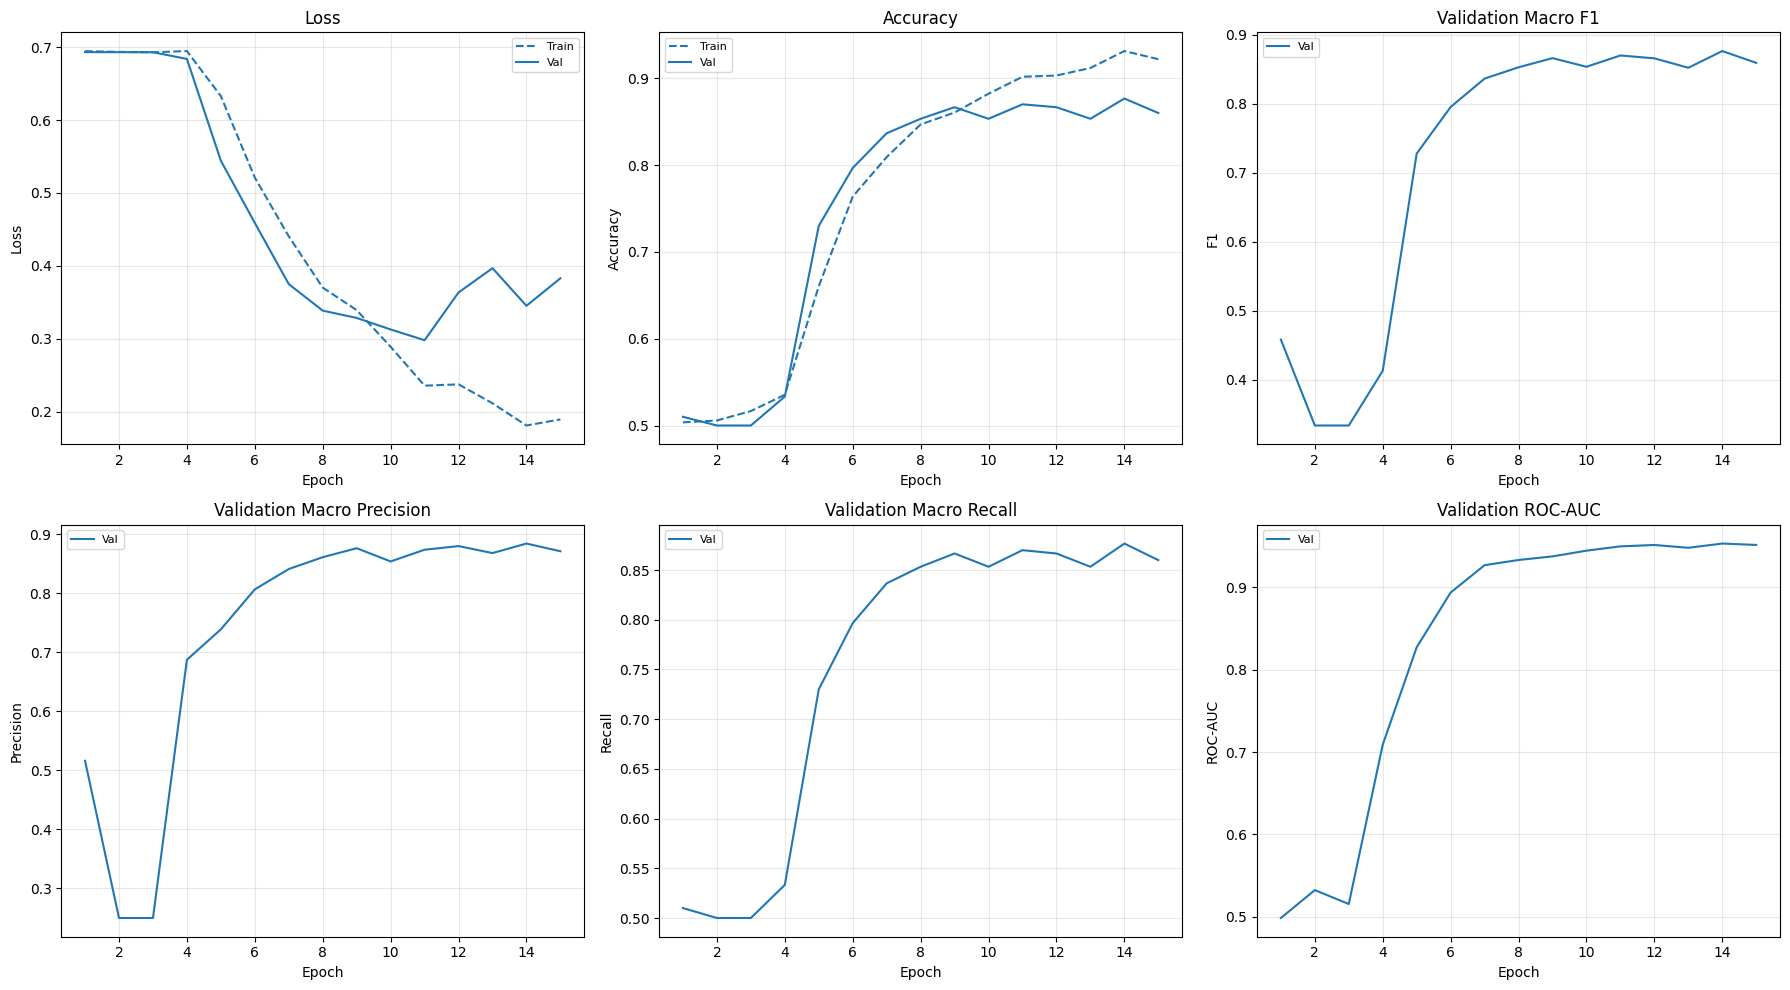

CLEAN MODEL -- BEST VALIDATION EPOCH SUMMARY
Best epoch: 14  (Phase 2 (fine-tuning))
  Val Loss     : 0.3452
  Val Accuracy : 0.8767
  Val Precision(macro): 0.8842
  Val Recall(macro)   : 0.8767
  Val F1(macro)       : 0.8761
  Val ROC-AUC         : 0.9534

(Consistency check passed: best_row's F1 matches the value returned by training.)


In [6]:
# ============================================================
# CELL 6: Clean validation
# ============================================================
# Training curves for the clean run, plus a summary of the epoch that was
# actually selected as "best" (by validation macro F1).

clean_df = pd.DataFrame(clean_history)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))


def plot_metric(ax, key_train, key_val, title, ylabel):
    if key_train and key_train in clean_df:
        ax.plot(clean_df["epoch"], clean_df[key_train], "--", label="Train", color="tab:blue")
    if key_val in clean_df:
        ax.plot(clean_df["epoch"], clean_df[key_val], label="Val", color="tab:blue")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)


plot_metric(axes[0, 0], "train_loss", "val_loss", "Loss", "Loss")
plot_metric(axes[0, 1], "train_acc", "val_accuracy", "Accuracy", "Accuracy")
plot_metric(axes[0, 2], None, "val_f1", "Validation Macro F1", "F1")
plot_metric(axes[1, 0], None, "val_precision", "Validation Macro Precision", "Precision")
plot_metric(axes[1, 1], None, "val_recall", "Validation Macro Recall", "Recall")
plot_metric(axes[1, 2], None, "val_roc_auc", "Validation ROC-AUC", "ROC-AUC")

plt.tight_layout()
plt.savefig("/kaggle/working/clean_training_curves.png", dpi=150)
plt.show()

best_row = clean_df.loc[clean_df["val_roc_auc"].idxmax()]
print("=" * 60)
print("CLEAN MODEL -- BEST VALIDATION EPOCH SUMMARY")
print("=" * 60)
print(f"Best epoch: {int(best_row['epoch'])}  ({best_row['phase']})")
print(f"  Val Loss     : {best_row['val_loss']:.4f}")
print(f"  Val Accuracy : {best_row['val_accuracy']:.4f}")
print(f"  Val Precision(macro): {best_row['val_precision']:.4f}")
print(f"  Val Recall(macro)   : {best_row['val_recall']:.4f}")
print(f"  Val F1(macro)       : {best_row['val_f1']:.4f}")
print(f"  Val ROC-AUC         : {best_row['val_roc_auc']:.4f}")
assert abs(best_row["val_roc_auc"] - clean_best_val_f1) < 1e-9, (
    "Mismatch between the best-F1 row found here and the value returned by "
    "run_staged_training -- checkpoint selection logic is inconsistent."
)
print("\n(Consistency check passed: best_row's F1 matches the value returned by training.)")


In [7]:
# ============================================================
# CELL 7: Best checkpoint loading
# ============================================================
# EXPLICIT FIX (per the brief): the best-validation-F1 checkpoint is loaded
# IN PLACE here, and this happens BEFORE any test-set evaluation anywhere
# in the notebook. Cell 5 saves a dict ({"model_state_dict", "val_f1",
# "epoch"}) rather than a bare state_dict, specifically so this cell can
# verify -- not just assume -- that the checkpoint being loaded really is
# the best one, and that it is not simply the last epoch's weights.

free_cuda_memory()

clean_checkpoint = torch.load(CONFIG["save_clean_checkpoint"], map_location=CONFIG["device"], weights_only=False)
clean_model.load_state_dict(clean_checkpoint["model_state_dict"])
clean_model.eval()

print(f"Loaded checkpoint from {CONFIG['save_clean_checkpoint']}")
print(f"  Saved at epoch {clean_checkpoint['epoch']} with validation ROC-AUC = {clean_checkpoint['val_score']:.4f}")

assert abs(clean_checkpoint["val_score"] - clean_best_val_f1) < 1e-9, (
    f"Checkpoint's recorded val_f1 ({clean_checkpoint['val_score']:.4f}) does not match "
    f"the best val_f1 tracked during training ({clean_best_val_f1:.4f}) -- "
    f"the reloaded model may NOT be the best-validation model. Investigate before evaluating."
)
print("Verified: this checkpoint's validation F1 matches the best value observed during training "
      "-- the model now in memory is the BEST validation checkpoint, not the last epoch's weights.")

last_epoch_in_history = int(clean_df["epoch"].max())
if clean_checkpoint["epoch"] < last_epoch_in_history:
    print(f"(Note: best epoch {clean_checkpoint['epoch']} is earlier than the final epoch "
          f"{last_epoch_in_history} run -- later epochs did not improve validation F1, so the "
          f"earlier, better checkpoint is correctly the one now loaded.)")


Loaded checkpoint from /kaggle/working/best_clean_model.pth
  Saved at epoch 14 with validation ROC-AUC = 0.9534
Verified: this checkpoint's validation F1 matches the best value observed during training -- the model now in memory is the BEST validation checkpoint, not the last epoch's weights.
(Note: best epoch 14 is earlier than the final epoch 15 run -- later epochs did not improve validation F1, so the earlier, better checkpoint is correctly the one now loaded.)


VALIDATION THRESHOLD SELECTION (clean model)
Youden's J threshold (reference only): 0.510
F1-grid-search threshold (FROZEN, used below): 0.480



FINAL CLEAN TEST EVALUATION
ROC-AUC (threshold-INDEPENDENT): 0.9348
PR-AUC  (threshold-INDEPENDENT): 0.9420

--- Threshold-DEPENDENT metrics @ 0.5 (default) ---
[Clean test @0.5] thr=0.500  Acc=0.8733  F1(macro)=0.8728  ROC-AUC=0.9348  PR-AUC=0.9420  BalAcc=0.8733  | TP=121 TN=141 FP=9 FN=29
  Real -> P=0.8294  R=0.9400  F1=0.8812
  Fake -> P=0.9308  R=0.8067  F1=0.8643

--- Threshold-DEPENDENT metrics @ 0.480 (validation-selected) ---
[Clean test @selected] thr=0.480  Acc=0.8700  F1(macro)=0.8695  ROC-AUC=0.9348  PR-AUC=0.9420  BalAcc=0.8700  | TP=121 TN=140 FP=10 FN=29
  Real -> P=0.8284  R=0.9333  F1=0.8777
  Fake -> P=0.9237  R=0.8067  F1=0.8612

Classification report @ selected threshold (0.480):
              precision    recall  f1-score   support

        Real       0.83      0.93      0.88       150
        Fake       0.92      0.81      0.86       150

    accuracy                           0.87       300
   macro avg       0.88      0.87      0.87       300
weighted avg    

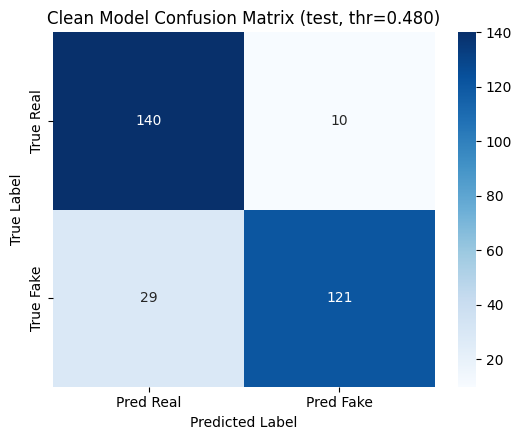


TP=121  TN=140  FP=10  FN=29


In [8]:
# ============================================================
# CELL 8: Final clean test evaluation
# ============================================================
# THRESHOLD HANDLING FIX (per the brief): the threshold is selected on the
# VALIDATION set ONLY, then frozen and applied exactly once to the test
# set. ROC-AUC is reported separately as the threshold-INDEPENDENT metric;
# everything else (accuracy/precision/recall/F1/confusion matrix) is
# threshold-DEPENDENT and is reported at both 0.5 and the selected
# threshold so the two are never conflated.

def get_raw_predictions(model, loader, use_amp=USE_AMP):
    model.eval()
    all_probs, all_labels = [], []
    with torch.no_grad():
        for videos, labels in tqdm(loader, desc="Evaluating", leave=False):
            videos = videos.to(CONFIG["device"], non_blocking=True)
            if use_amp:
                with torch.amp.autocast("cuda"):
                    logits = model(videos)
            else:
                logits = model(videos)
            all_probs.extend(torch.sigmoid(logits).cpu().numpy())
            all_labels.extend(labels.numpy())
    return np.array(all_labels).astype(int), np.array(all_probs)


# ---- Threshold selection on VALIDATION only ----
clean_val_labels, clean_val_probs = get_raw_predictions(clean_model, val_loader)

# (a) Youden's J statistic (reported for reference/comparison)
fpr, tpr, roc_thresholds = roc_curve(clean_val_labels, clean_val_probs)
youden_j = tpr - fpr
youden_threshold = float(roc_thresholds[np.argmax(youden_j)])

# (b) Grid search maximizing macro F1 (this is the threshold actually FROZEN
# and used below -- kept consistent with macro F1 being the model-selection
# metric throughout the notebook)
thresholds = np.arange(CONFIG["threshold_search_min"], CONFIG["threshold_search_max"] + 1e-9,
                        CONFIG["threshold_search_step"])
threshold_rows = [{"threshold": float(t),
                    **{k: v for k, v in compute_metrics(clean_val_labels, clean_val_probs, float(t)).items()
                       if k in ("f1", "accuracy")}}
                   for t in thresholds]
threshold_df = pd.DataFrame(threshold_rows)
clean_selected_threshold = float(threshold_df.loc[threshold_df["f1"].idxmax(), "threshold"])

print("=" * 60)
print("VALIDATION THRESHOLD SELECTION (clean model)")
print("=" * 60)
print(f"Youden's J threshold (reference only): {youden_threshold:.3f}")
print(f"F1-grid-search threshold (FROZEN, used below): {clean_selected_threshold:.3f}")

# ---- Test set: raw predictions computed ONCE, reused for every threshold ----
clean_test_labels, clean_test_probs = get_raw_predictions(clean_model, test_loader)

clean_test_metrics_default = compute_metrics(clean_test_labels, clean_test_probs, threshold=0.5)
clean_test_metrics_selected = compute_metrics(clean_test_labels, clean_test_probs, threshold=clean_selected_threshold)

print("\n" + "=" * 60)
print("FINAL CLEAN TEST EVALUATION")
print("=" * 60)
print(f"ROC-AUC (threshold-INDEPENDENT): {clean_test_metrics_default['roc_auc']:.4f}")
print(f"PR-AUC  (threshold-INDEPENDENT): {clean_test_metrics_default['pr_auc']:.4f}")

print("\n--- Threshold-DEPENDENT metrics @ 0.5 (default) ---")
print_metrics("Clean test @0.5", clean_test_metrics_default)
print(f"  Real -> P={clean_test_metrics_default['precision_real']:.4f}  "
      f"R={clean_test_metrics_default['recall_real']:.4f}  F1={clean_test_metrics_default['f1_real']:.4f}")
print(f"  Fake -> P={clean_test_metrics_default['precision_fake']:.4f}  "
      f"R={clean_test_metrics_default['recall_fake']:.4f}  F1={clean_test_metrics_default['f1_fake']:.4f}")

print(f"\n--- Threshold-DEPENDENT metrics @ {clean_selected_threshold:.3f} (validation-selected) ---")
print_metrics("Clean test @selected", clean_test_metrics_selected)
print(f"  Real -> P={clean_test_metrics_selected['precision_real']:.4f}  "
      f"R={clean_test_metrics_selected['recall_real']:.4f}  F1={clean_test_metrics_selected['f1_real']:.4f}")
print(f"  Fake -> P={clean_test_metrics_selected['precision_fake']:.4f}  "
      f"R={clean_test_metrics_selected['recall_fake']:.4f}  F1={clean_test_metrics_selected['f1_fake']:.4f}")

preds_selected = (clean_test_probs >= clean_selected_threshold).astype(int)
print(f"\nClassification report @ selected threshold ({clean_selected_threshold:.3f}):")
print(classification_report(clean_test_labels, preds_selected, target_names=["Real", "Fake"]))

cm = confusion_matrix(clean_test_labels, preds_selected, labels=[0, 1])
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred Real', 'Pred Fake'], yticklabels=['True Real', 'True Fake'])
plt.title(f"Clean Model Confusion Matrix (test, thr={clean_selected_threshold:.3f})")
plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.tight_layout()
plt.savefig("/kaggle/working/clean_confusion_matrix.png", dpi=150)
plt.show()

print(f"\nTP={clean_test_metrics_selected['tp']}  TN={clean_test_metrics_selected['tn']}  "
      f"FP={clean_test_metrics_selected['fp']}  FN={clean_test_metrics_selected['fn']}")


In [9]:
# ============================================================
# CELL 9: FGSM sanity check
# ============================================================
# This cell both DEFINES the FGSM attack and immediately VERIFIES it, before
# it is ever used for adversarial fine-tuning (Cell 11). Per the brief: do
# not assume the attack is correct just because it runs -- prove it.

# Unchanged in approach from the working notebook: attacks operate on the
# complete [B, T, C, H, W] video tensor after normalization, convert
# pixel-space epsilon/alpha into normalized-space bounds via the ImageNet
# std, run under autocast, and freeze BatchNorm/Dropout while forcing any
# LSTM/GRU/RNN submodule to stay in train() mode so cuDNN permits the
# backward pass needed to compute the input gradient. Fully architecture-
# agnostic, so this works unchanged against the new attention-pooling model.
#
# The dataset already returns ImageNet-normalized video tensors of shape
# [B, T, 3, 224, 224]. All attacks below operate directly on that
# normalized tensor and perturb every frame of every video consistently.
#
# Because the tensors are normalized, an epsilon specified in pixel space
# (e.g. 4/255) does NOT correspond to the same epsilon in normalized space.
# We convert per-channel using the ImageNet std:
#
#     epsilon_normalized[c] = epsilon_pixel / std[c]
#     alpha_normalized[c]   = alpha_pixel   / std[c]
#
# MEMORY NOTE (fixes CUDA OOM seen at ~14.5/14.56 GiB on the first batch):
# With seq_len=16, a single forward pass already pushes batch_size*seq_len
# (e.g. 8*16=128) images through EfficientNet-B1 at once. The attack's
# forward pass previously ran in full FP32 (no autocast), which uses
# roughly 2x the activation memory of the FP16 forward pass used
# everywhere else in the notebook. That FP32 attack graph, combined with
# holding a second full graph for training right after it, is what
# exhausted the GPU. The attacks below now run under the SAME autocast
# policy as the rest of the pipeline. Autograd still produces a correct
# (FP32) gradient for the FP32 leaf input `x` even though the forward
# math runs in FP16 -- this is the same mechanism PyTorch AMP already
# relies on for parameter gradients. The only trade-off is that a
# vanishingly small number of FP16-underflowed gradient entries may end
# up with a zero sign (a slightly weaker, not incorrect, perturbation at
# those pixels) -- acceptable for FGSM/PGD, which only use the sign.

import torch
import torch.nn as nn

# Renamed (was IMAGENET_MEAN/IMAGENET_STD) to avoid colliding with Cell 1's
# identically-named globals, which are plain 3-element lists used for
# per-frame torchvision normalization in the Dataset class -- reusing the
# same names here for a differently-shaped (5D, video-tensor-broadcastable)
# tensor previously overwrote Cell 1's copies as soon as this cell ran,
# causing a shape-mismatch crash the first time the DataLoader actually
# called Dataset.__getitem__ (lazily, only once training started).
_ATTACK_IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 1, 3, 1, 1)
_ATTACK_IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 1, 3, 1, 1)


def _prepare_model_for_attack(model):
    """
    Puts BatchNorm/Dropout into eval mode (frozen running stats,
    deterministic) for attack-generation, WHILE forcing any RNN-based
    submodule (LSTM/GRU/RNN) to stay in train() mode.

    This is required because cuDNN's fused RNN kernels only support a
    backward pass when the RNN module's `.training` flag is True; calling
    the whole model's `.eval()` (as attack generation would otherwise want,
    to freeze BatchNorm/Dropout) also flips the LSTM into its
    inference-only cuDNN descriptor, which then raises:
    "RuntimeError: cudnn RNN backward can only be called in training mode"
    the moment we call `torch.autograd.grad(loss, x, ...)`.

    Forcing just the RNN submodules back to train() after the global
    eval() sidesteps that, without reintroducing BatchNorm-statistics
    corruption or dropout noise into the attack.

    Returns a dict of {module: previous_training_bool} so the exact
    original mode of every submodule can be restored afterward.
    """
    prev_modes = {m: m.training for m in model.modules()}
    model.eval()
    for m in model.modules():
        if isinstance(m, (nn.LSTM, nn.GRU, nn.RNN)):
            m.train()
            # Temporarily disable dropout to ensure deterministic gradients
            m._stored_dropout = m.dropout 
            m.dropout = 0.0
    return prev_modes


def _restore_model_modes(model, prev_modes):
    """Restores every submodule's `.training` flag to what it was before
    `_prepare_model_for_attack` ran."""
    for m in model.modules():
        if m in prev_modes:
            m.train(prev_modes[m])
        if isinstance(m, (nn.LSTM, nn.GRU, nn.RNN)) and hasattr(m, '_stored_dropout'):
            m.dropout = m._stored_dropout
            del m._stored_dropout


def _get_norm_bounds(device):
    """Returns per-channel min/max of the normalized input space (i.e. the
    normalized values that correspond to raw pixel values 0 and 1)."""
    mean = _ATTACK_IMAGENET_MEAN.to(device)
    std = _ATTACK_IMAGENET_STD.to(device)
    valid_min = (0.0 - mean) / std
    valid_max = (1.0 - mean) / std
    return valid_min, valid_max


def _epsilon_to_normalized(epsilon_pixel, device):
    """Converts a scalar pixel-space epsilon into a per-channel normalized-space
    tensor of shape [1, 1, 3, 1, 1] broadcastable against [B, T, C, H, W]."""
    std = _ATTACK_IMAGENET_STD.to(device)
    return epsilon_pixel / std


def fgsm_attack(model, videos, labels, epsilon, criterion=None, use_amp=None):
    """
    Fast Gradient Sign Method, applied over the COMPLETE video tensor
    [B, T, C, H, W]. Every frame of a given video is perturbed with the
    same-sign gradient step (i.e. the whole clip is attacked jointly,
    since the gradient already flows through all T frames via the LSTM).

    Args:
        model: FFPPDeepfakeDetector (or any model with matching forward signature)
        videos: clean input tensor [B, T, C, H, W], ImageNet-normalized, NOT requiring grad
        labels: ground-truth labels [B]
        epsilon: perturbation budget in PIXEL space (e.g. 4/255)
        criterion: loss function (defaults to BCEWithLogitsLoss)
        use_amp: whether to run the internal forward pass under autocast
                 (defaults to the global USE_AMP flag set in Cell 5 if available,
                 otherwise True when on CUDA)

    Returns:
        adv_videos: adversarially perturbed video tensor, detached, same shape as `videos`
    """
    if criterion is None:
        criterion = nn.BCEWithLogitsLoss()

    device = videos.device
    if use_amp is None:
        use_amp = globals().get("USE_AMP", device.type == "cuda")

    # Freeze BatchNorm/Dropout for attack generation, but keep any LSTM/GRU/RNN
    # submodule in train() mode so cuDNN's RNN backward kernel is available
    # (see _prepare_model_for_attack docstring above).
    prev_modes = _prepare_model_for_attack(model)

    # Work on a fresh leaf tensor that requires grad; never mutate `videos` in-place.
    x = videos.clone().detach().to(device)
    x.requires_grad_(True)

    if use_amp:
        temp_scaler = torch.amp.GradScaler("cuda")
        with torch.amp.autocast("cuda"):
            logits = model(x)
            loss = criterion(logits, labels)
        
        # Scale loss before computing gradients to prevent FP16 underflow
        scaled_grad = torch.autograd.grad(temp_scaler.scale(loss), x, retain_graph=False, create_graph=False)[0]
        # Unscale the gradients back to normal magnitude
        grad = scaled_grad / temp_scaler.get_scale()
    else:
        logits = model(x)
        loss = criterion(logits, labels)
        grad = torch.autograd.grad(loss, x, retain_graph=False, create_graph=False)[0]

    epsilon_norm = _epsilon_to_normalized(epsilon, device)  # [1,1,3,1,1]
    valid_min, valid_max = _get_norm_bounds(device)

    with torch.no_grad():
        x_adv = x + epsilon_norm * grad.sign()
        # Project the perturbation back into the epsilon ball around the clean input
        perturbation = torch.clamp(x_adv - videos, min=-epsilon_norm, max=epsilon_norm)
        x_adv = videos + perturbation
        # Keep the adversarial example within the valid (un-normalized 0..1 pixel) range
        x_adv = torch.max(torch.min(x_adv, valid_max), valid_min)

    x_adv = x_adv.detach()

    # Clear any residual grads accumulated on model parameters during the backward call,
    # and drop references to the (now unneeded) forward/backward graph promptly.
    model.zero_grad(set_to_none=True)
    del x, logits, loss, grad

    _restore_model_modes(model, prev_modes)

    return x_adv



def evaluate_attack(model, loader, attack_fn, threshold, use_amp=USE_AMP):
    """Generic attack evaluator, reused in Cells 10/12. attack_fn(model, videos,
    labels)->adv_videos, or None for a clean (unattacked) pass."""
    model.eval()
    all_probs, all_labels = [], []
    for videos, labels in tqdm(loader, desc="Evaluating attack", leave=False):
        videos = videos.to(CONFIG["device"], non_blocking=True)
        labels_dev = labels.to(CONFIG["device"], non_blocking=True)
        eval_videos = attack_fn(model, videos, labels_dev) if attack_fn is not None else videos
        with torch.no_grad():
            if use_amp:
                with torch.amp.autocast("cuda"):
                    logits = model(eval_videos)
            else:
                logits = model(eval_videos)
        all_probs.extend(torch.sigmoid(logits).cpu().numpy())
        all_labels.extend(labels.numpy())
    return compute_metrics(np.array(all_labels).astype(int), np.array(all_probs), threshold=threshold)


def fgsm_sanity_check(model, loader, epsilons, n_samples=8):
    """Per-sample diagnostic on CORRECTLY-CLASSIFIED clean samples: reports
    clean/adv loss, clean/adv probability, predictions, and the ACTUAL
    L-infinity perturbation in pixel space (verified against the epsilon
    bound). Also checks that epsilon=0 is an exact no-op."""
    model.eval()
    videos, labels = next(iter(loader))
    videos = videos.to(CONFIG["device"])
    labels = labels.to(CONFIG["device"])

    with torch.no_grad():
        clean_logits = model(videos)
        clean_probs = torch.sigmoid(clean_logits)
        clean_preds = (clean_probs >= 0.5).float()
        correct_mask = (clean_preds == labels)

    correct_idx = torch.nonzero(correct_mask, as_tuple=True)[0][:n_samples]
    if len(correct_idx) == 0:
        print("WARNING: no correctly-classified samples in this batch -- "
              "sanity check has nothing to report for this batch.")
        return None

    sample_videos = videos[correct_idx]
    sample_labels = labels[correct_idx]
    print(f"Running FGSM sanity check on {len(correct_idx)} correctly-classified clean samples.")

    std_t = torch.tensor(IMAGENET_STD, device=videos.device).view(1, 1, 3, 1, 1)
    results = []

    for eps in epsilons:
        if eps == 0.0:
            adv_videos = sample_videos.clone()
            max_diff = (adv_videos - sample_videos).abs().max().item()
            assert max_diff < 1e-6, f"FGSM at epsilon=0 should be a no-op, but max diff={max_diff}"
        else:
            adv_videos = fgsm_attack(model, sample_videos, sample_labels, epsilon=eps, criterion=criterion)

        with torch.no_grad():
            clean_logits_s = model(sample_videos)
            adv_logits_s = model(adv_videos)
            clean_loss_s = criterion(clean_logits_s, sample_labels).item()
            adv_loss_s = criterion(adv_logits_s, sample_labels).item()
            clean_probs_s = torch.sigmoid(clean_logits_s)
            adv_probs_s = torch.sigmoid(adv_logits_s)
            clean_preds_s = (clean_probs_s >= 0.5).float()
            adv_preds_s = (adv_probs_s >= 0.5).float()

        pixel_diff = (adv_videos - sample_videos) * std_t  # undo the /std of normalization
        actual_linf_pixel = pixel_diff.abs().max().item()
        flipped = (adv_preds_s != clean_preds_s).float().mean().item()

        print(f"\n  epsilon={eps:.4f} (px):")
        print(f"    clean_loss={clean_loss_s:.4f}  adv_loss={adv_loss_s:.4f}  "
              f"({'loss increased -- OK for untargeted FGSM' if adv_loss_s > clean_loss_s or eps == 0.0 else 'loss DID NOT increase -- suspicious!'})")
        print(f"    mean clean P(fake)={clean_probs_s.mean().item():.4f}  "
              f"mean adv P(fake)={adv_probs_s.mean().item():.4f}")
        print(f"    fraction of predictions flipped by the attack: {flipped:.2%}")
        print(f"    actual L-inf perturbation (pixel space): {actual_linf_pixel:.5f}  (bound={eps:.5f})  "
              f"{'OK' if actual_linf_pixel <= eps + 1e-6 else 'BOUND VIOLATION!'}")

        results.append({
            "epsilon_px": eps, "clean_loss": clean_loss_s, "adv_loss": adv_loss_s,
            "mean_clean_prob": clean_probs_s.mean().item(), "mean_adv_prob": adv_probs_s.mean().item(),
            "fraction_flipped": flipped, "actual_linf_pixel": actual_linf_pixel,
            "within_epsilon_bound": actual_linf_pixel <= eps + 1e-6,
        })

    return pd.DataFrame(results)


print("=" * 60)
print("FGSM SANITY CHECK (on the CLEAN model, BEFORE any adversarial fine-tuning)")
print("=" * 60)
fgsm_sanity_df = fgsm_sanity_check(clean_model, test_loader, CONFIG["sanity_check_epsilons"],
                                    n_samples=CONFIG["sanity_check_n_samples"])
print("\nSummary:")
print(fgsm_sanity_df.to_string(index=False))
assert fgsm_sanity_df["within_epsilon_bound"].all(), (
    "One or more FGSM perturbations exceeded their epsilon bound -- fix the attack "
    "implementation before using it for adversarial fine-tuning."
)

# ---- Broader check: full-test-set accuracy vs epsilon, on the CLEAN model ----
print("\nBroader check: full-test-set accuracy under increasing FGSM epsilon (clean model):")
acc_by_eps_rows = []
for eps in CONFIG["sanity_check_epsilons"]:
    if eps == 0.0:
        labels_, probs_ = get_raw_predictions(clean_model, test_loader)
        m_ = compute_metrics(labels_, probs_, threshold=0.5)
    else:
        attack_fn = lambda m, v, l, eps=eps: fgsm_attack(m, v, l, epsilon=eps, criterion=criterion)
        m_ = evaluate_attack(clean_model, test_loader, attack_fn, threshold=0.5)
    acc_by_eps_rows.append({"epsilon": eps, "accuracy": m_["accuracy"], "f1": m_["f1"], "roc_auc": m_["roc_auc"]})

acc_by_eps_df = pd.DataFrame(acc_by_eps_rows)
print(acc_by_eps_df.to_string(index=False))

accs = acc_by_eps_df["accuracy"].tolist()
is_reasonable = all(accs[i] >= accs[i + 1] - 0.05 for i in range(len(accs) - 1))  # small tolerance for noise
if is_reasonable:
    print("\nPASS: clean-model accuracy does not meaningfully INCREASE as epsilon grows -- "
          "FGSM is behaving like a genuine untargeted attack.")
else:
    print("\nWARNING: clean-model accuracy increased noticeably at some epsilon step. This would "
          "indicate a bug in the FGSM implementation itself (independent of adversarial training) "
          "-- investigate before proceeding to Cell 11.")

FGSM SANITY CHECK (on the CLEAN model, BEFORE any adversarial fine-tuning)
Running FGSM sanity check on 7 correctly-classified clean samples.

  epsilon=0.0000 (px):
    clean_loss=0.0171  adv_loss=0.0171  (loss increased -- OK for untargeted FGSM)
    mean clean P(fake)=0.5630  mean adv P(fake)=0.5630
    fraction of predictions flipped by the attack: 0.00%
    actual L-inf perturbation (pixel space): 0.00000  (bound=0.00000)  OK

  epsilon=0.0078 (px):
    clean_loss=0.0171  adv_loss=6.5017  (loss increased -- OK for untargeted FGSM)
    mean clean P(fake)=0.5630  mean adv P(fake)=0.4302
    fraction of predictions flipped by the attack: 100.00%
    actual L-inf perturbation (pixel space): 0.00784  (bound=0.00784)  OK

  epsilon=0.0157 (px):
    clean_loss=0.0171  adv_loss=5.7719  (loss increased -- OK for untargeted FGSM)
    mean clean P(fake)=0.5630  mean adv P(fake)=0.4216
    fraction of predictions flipped by the attack: 100.00%
    actual L-inf perturbation (pixel space): 0.01

 epsilon  accuracy       f1  roc_auc
0.000000  0.873333 0.872768 0.934800
0.007843  0.003333 0.003322 0.000000
0.015686  0.010000 0.009901 0.000178
0.031373  0.373333 0.271845 0.006267



In [10]:
# ============================================================
# CELL 10a: PGD sanity check
# ============================================================
# Defines PGD and verifies it the same way Cell 9 verified FGSM: perturbation
# stays within the epsilon ball, the model is in eval mode during the attack
# (via _prepare_model_for_attack, shared with FGSM), gradients are computed
# from the TRUE labels (no label leakage from the model's own predictions),
# and -- as a cross-check -- PGD should be AT LEAST as effective as FGSM at
# the same epsilon, since it is a strictly more thorough iterative search
# within the same perturbation ball.

def pgd_attack(model, videos, labels, epsilon, alpha, steps, criterion=None,
                random_start=True, use_amp=None):
    """
    Projected Gradient Descent attack over the COMPLETE video tensor
    [B, T, C, H, W]. Used ONLY for stronger robustness evaluation
    (never for training, to keep Kaggle runtime practical).
    """
    if criterion is None:
        criterion = nn.BCEWithLogitsLoss()

    device = videos.device
    if use_amp is None:
        use_amp = globals().get("USE_AMP", device.type == "cuda")

    # Same reasoning as fgsm_attack: freeze BatchNorm/Dropout but force any
    # LSTM/GRU/RNN submodule to stay in train() mode so cuDNN's RNN backward
    # kernel is available for each of the PGD steps below.
    prev_modes = _prepare_model_for_attack(model)

    epsilon_norm = _epsilon_to_normalized(epsilon, device)   # [1,1,3,1,1]
    alpha_norm = _epsilon_to_normalized(alpha, device)       # [1,1,3,1,1]
    valid_min, valid_max = _get_norm_bounds(device)

    videos_clean = videos.clone().detach()

    if random_start:
        rand_noise = (torch.rand_like(videos_clean) * 2 - 1) * epsilon_norm
        x_adv = videos_clean + rand_noise
        x_adv = torch.max(torch.min(x_adv, valid_max), valid_min)
    else:
        x_adv = videos_clean.clone()

    for _ in range(steps):
        x_adv = x_adv.detach()
        x_adv.requires_grad_(True)

        if use_amp:
            temp_scaler = torch.amp.GradScaler("cuda")
            with torch.amp.autocast("cuda"):
                logits = model(x_adv)
                loss = criterion(logits, labels)
                
            # Scale and unscale to prevent FP16 underflow
            scaled_grad = torch.autograd.grad(temp_scaler.scale(loss), x_adv, retain_graph=False, create_graph=False)[0]
            grad = scaled_grad / temp_scaler.get_scale()
        else:
            logits = model(x_adv)
            loss = criterion(logits, labels)
            grad = torch.autograd.grad(loss, x_adv, retain_graph=False, create_graph=False)[0]

        with torch.no_grad():
            x_adv = x_adv + alpha_norm * grad.sign()
            # Project back into the epsilon ball around the ORIGINAL clean input
            perturbation = torch.clamp(x_adv - videos_clean, min=-epsilon_norm, max=epsilon_norm)
            x_adv = videos_clean + perturbation
            x_adv = torch.max(torch.min(x_adv, valid_max), valid_min)

        del logits, loss, grad

    model.zero_grad(set_to_none=True)
    _restore_model_modes(model, prev_modes)

    return x_adv.detach()


print("Adversarial attack utilities ready: fgsm_attack(), pgd_attack()")


def pgd_sanity_check(model, loader, epsilon, alpha, steps, n_samples=8):
    model.eval()
    videos, labels = next(iter(loader))
    videos = videos.to(CONFIG["device"])
    labels = labels.to(CONFIG["device"])

    with torch.no_grad():
        clean_logits = model(videos)
        clean_preds = (torch.sigmoid(clean_logits) >= 0.5).float()
        correct_mask = (clean_preds == labels)
    correct_idx = torch.nonzero(correct_mask, as_tuple=True)[0][:n_samples]
    if len(correct_idx) == 0:
        print("WARNING: no correctly-classified samples in this batch.")
        return

    sample_videos = videos[correct_idx]
    sample_labels = labels[correct_idx]

    # No-op check: epsilon=0, no random start -> PGD should not move the input at all
    adv_zero = pgd_attack(model, sample_videos, sample_labels, epsilon=0.0, alpha=alpha,
                           steps=steps, random_start=False)
    max_diff_zero = (adv_zero - sample_videos).abs().max().item()
    assert max_diff_zero < 1e-6, f"PGD at epsilon=0 (no random start) should be a no-op, got max diff={max_diff_zero}"
    print(f"epsilon=0, random_start=False: identity check passed (max diff={max_diff_zero:.2e})")

    # Real PGD run at the target epsilon
    adv_videos = pgd_attack(model, sample_videos, sample_labels, epsilon=epsilon, alpha=alpha,
                             steps=steps, random_start=True)

    std_t = torch.tensor(IMAGENET_STD, device=videos.device).view(1, 1, 3, 1, 1)
    pixel_diff = (adv_videos - sample_videos) * std_t
    actual_linf_pixel = pixel_diff.abs().max().item()
    print(f"\n{steps}-step PGD @ epsilon={epsilon:.4f}, alpha={alpha:.4f}:")
    print(f"  actual L-inf perturbation (pixel space): {actual_linf_pixel:.5f}  (bound={epsilon:.5f})  "
          f"{'OK' if actual_linf_pixel <= epsilon + 1e-6 else 'BOUND VIOLATION!'}")
    assert actual_linf_pixel <= epsilon + 1e-6, "PGD perturbation exceeded its epsilon bound!"

    with torch.no_grad():
        clean_logits_s = model(sample_videos)
        adv_logits_s = model(adv_videos)
        clean_loss_s = criterion(clean_logits_s, sample_labels).item()
        adv_loss_s = criterion(adv_logits_s, sample_labels).item()
    print(f"  clean_loss={clean_loss_s:.4f}  adv_loss={adv_loss_s:.4f}  "
          f"({'loss increased -- OK' if adv_loss_s > clean_loss_s else 'loss DID NOT increase -- suspicious!'})")


print("=" * 60)
print("PGD SANITY CHECK (on the CLEAN model)")
print("=" * 60)
pgd_sanity_check(clean_model, test_loader, epsilon=4 / 255, alpha=CONFIG["adv_alpha"], steps=3,
                  n_samples=CONFIG["sanity_check_n_samples"])
pgd_sanity_check(clean_model, test_loader, epsilon=4 / 255, alpha=CONFIG["adv_alpha"], steps=5,
                  n_samples=CONFIG["sanity_check_n_samples"])

# ---- Cross-check: PGD should be AT LEAST as strong as FGSM at the same epsilon ----
print("\n" + "=" * 60)
print("CROSS-CHECK: PGD vs FGSM strength at epsilon=4/255 (clean model, full test set)")
print("=" * 60)

fgsm4_fn = lambda m, v, l: fgsm_attack(m, v, l, epsilon=4 / 255, criterion=criterion)
pgd3_fn = lambda m, v, l: pgd_attack(m, v, l, epsilon=4 / 255, alpha=CONFIG["adv_alpha"], steps=3, criterion=criterion)
pgd5_fn = lambda m, v, l: pgd_attack(m, v, l, epsilon=4 / 255, alpha=CONFIG["adv_alpha"], steps=5, criterion=criterion)

clean_fgsm4 = evaluate_attack(clean_model, test_loader, fgsm4_fn, threshold=0.5)
clean_pgd3 = evaluate_attack(clean_model, test_loader, pgd3_fn, threshold=0.5)
clean_pgd5 = evaluate_attack(clean_model, test_loader, pgd5_fn, threshold=0.5)

print(f"Clean model, FGSM 4/255 : accuracy={clean_fgsm4['accuracy']:.4f}  F1={clean_fgsm4['f1']:.4f}")
print(f"Clean model, PGD-3 4/255: accuracy={clean_pgd3['accuracy']:.4f}  F1={clean_pgd3['f1']:.4f}")
print(f"Clean model, PGD-5 4/255: accuracy={clean_pgd5['accuracy']:.4f}  F1={clean_pgd5['f1']:.4f}")

if clean_pgd3["accuracy"] <= clean_fgsm4["accuracy"] + 0.02 and clean_pgd5["accuracy"] <= clean_pgd3["accuracy"] + 0.02:
    print("\nPASS: PGD is at least as effective as FGSM, and PGD-5 is at least as effective as PGD-3 "
          "-- attack strength ordering is as expected (iterative >= single-step, more steps >= fewer steps).")
else:
    print("\nWARNING: PGD did not behave as at least as strong as FGSM (or PGD-5 vs PGD-3) on the "
          "CLEAN model. Since this is measured on the clean (not adversarially trained) model, this "
          "would point to a bug in the PGD implementation itself, not a property of adversarial "
          "training -- investigate before proceeding.")

Adversarial attack utilities ready: fgsm_attack(), pgd_attack()
PGD SANITY CHECK (on the CLEAN model)
epsilon=0, random_start=False: identity check passed (max diff=0.00e+00)

3-step PGD @ epsilon=0.0157, alpha=0.0039:
  actual L-inf perturbation (pixel space): 0.01569  (bound=0.01569)  OK
  clean_loss=0.0171  adv_loss=6.5925  (loss increased -- OK)
epsilon=0, random_start=False: identity check passed (max diff=0.00e+00)

5-step PGD @ epsilon=0.0157, alpha=0.0039:
  actual L-inf perturbation (pixel space): 0.01569  (bound=0.01569)  OK
  clean_loss=0.0171  adv_loss=6.8438  (loss increased -- OK)

CROSS-CHECK: PGD vs FGSM strength at epsilon=4/255 (clean model, full test set)


Clean model, FGSM 4/255 : accuracy=0.0100  F1=0.0099
Clean model, PGD-3 4/255: accuracy=0.0000  F1=0.0000
Clean model, PGD-5 4/255: accuracy=0.0067  F1=0.0066

PASS: PGD is at least as effective as FGSM, and PGD-5 is at least as effective as PGD-3 -- attack strength ordering is as expected (iterative >= single-step, more steps >= fewer steps).


In [11]:
# ============================================================
# CELL 11: Adversarial fine-tuning
# ============================================================
# Per the brief: do NOT train an adversarial model from scratch with an
# aggressive 50/50 loss. Instead: initialize from the best CLEAN checkpoint
# and fine-tune conservatively (epsilon=2/255, clean_loss_weight=0.8,
# adv_loss_weight=0.2 by default), selecting the best epoch by CLEAN
# validation macro F1 -- so a robustness gain can never be "bought" by
# silently destroying clean performance. FGSM validation accuracy is also
# tracked every epoch, purely for visibility into robustness progress.

def validate_epoch_adversarial(model, loader, criterion, epsilon, threshold=0.5, use_amp=USE_AMP):
    # model.eval() locks the BatchNorm running statistics so the adversarial 
    # noise generated below does not permanently corrupt the model's state.
    model.eval()
    all_probs, all_labels = [], []
    running_loss, n = 0.0, 0
    
    for videos, labels in tqdm(loader, desc="Validating (FGSM)", leave=False):
        videos = videos.to(CONFIG["device"], non_blocking=True)
        labels = labels.to(CONFIG["device"], non_blocking=True)
        
        # fgsm_attack handles its own AMP scaling internally (via the fix in Cell 9),
        # so no external GradScaler needs to be passed here.
        adv_videos = fgsm_attack(model, videos, labels, epsilon=epsilon, criterion=criterion, use_amp=use_amp)
        
        with torch.no_grad():
            if use_amp:
                with torch.amp.autocast("cuda"):
                    logits = model(adv_videos)
                    loss = criterion(logits, labels)
            else:
                logits = model(adv_videos)
                loss = criterion(logits, labels)
                
        bs = videos.size(0)
        running_loss += loss.item() * bs
        n += bs
        all_probs.extend(torch.sigmoid(logits).cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        del adv_videos
        
    m = compute_metrics(all_labels, all_probs, threshold=threshold)
    m["loss"] = running_loss / n
    return m


def finetune_adversarial(epsilon, clean_w, adv_w, epochs, tag, save_path=None):
    """STEP 3+4: initialize a FRESH model from the best clean checkpoint,
    match its trainable-parameter configuration (last N backbone blocks
    unfrozen, same as where clean training ended up), then fine-tune with
    the combined clean+adversarial objective. Returns (model, history,
    best_clean_val_f1)."""
    set_global_seed(CONFIG["seed"])

    ft_model = build_model()
    ft_model.load_state_dict(clean_checkpoint["model_state_dict"])
    ft_model.unfreeze_last_n_blocks(CONFIG["unfreeze_last_n_blocks"])  # match clean training's end state

    optimizer = build_optimizer(ft_model)
    for g in optimizer.param_groups:           # much smaller LR than clean training
        g["lr"] *= CONFIG["art_lr_scale"]
    scheduler = build_scheduler(optimizer, epochs)
    scaler = torch.amp.GradScaler("cuda") if USE_AMP else None

    history = []
    best_val_f1 = -1.0

    print(f"\n{'=' * 60}\n{tag}: epsilon={epsilon:.4f}  clean_w={clean_w}  adv_w={adv_w}  "
          f"epochs={epochs}\n{'=' * 60}")

    for epoch in range(1, epochs + 1):
        train_metrics = train_epoch(
            ft_model, train_loader, optimizer, criterion, scaler, USE_AMP,
            adversarial=True, epsilon=epsilon, adv_loss_weight=adv_w, clean_loss_weight=clean_w,
            grad_clip_norm=CONFIG["grad_clip_norm"],
        )
        val_metrics = validate_epoch(ft_model, val_loader, criterion, threshold=0.5, use_amp=USE_AMP)
        val_adv_metrics = validate_epoch_adversarial(ft_model, val_loader, criterion,
                                                      epsilon=epsilon, threshold=0.5, use_amp=USE_AMP)
        scheduler.step(val_metrics["f1"])

        print(f"\nEpoch {epoch}/{epochs}")
        print(f"  Train: total={train_metrics['loss']:.4f} clean={train_metrics['clean_loss']:.4f} "
              f"adv={train_metrics['adv_loss']:.4f} acc={train_metrics['acc']:.4f}")
        print(f"  Val (clean): acc={val_metrics['accuracy']:.4f} F1={val_metrics['f1']:.4f} "
              f"ROC-AUC={val_metrics['roc_auc']:.4f}")
        print(f"  Val (FGSM eps={epsilon:.4f}): acc={val_adv_metrics['accuracy']:.4f} "
              f"F1={val_adv_metrics['f1']:.4f}")

        history.append({
            "epoch": epoch, "tag": tag,
            **{f"train_{k}": v for k, v in train_metrics.items()},
            **{f"val_{k}": v for k, v in val_metrics.items()},
            **{f"val_adv_{k}": v for k, v in val_adv_metrics.items()},
        })

        # Selection metric is CLEAN validation F1 -- a robustness gain must
        # not come at the cost of the checkpoint that would have been chosen anyway.
        if selection_score(val_metrics) > best_val_f1:
            best_val_f1 = selection_score(val_metrics)
            if save_path:
                torch.save({"model_state_dict": ft_model.state_dict(),
                            "val_score": best_val_f1, "epoch": epoch,
                            "epsilon": epsilon, "clean_w": clean_w, "adv_w": adv_w}, save_path)
                print(f"  --> Best {tag} model saved (clean val ROC-AUC={best_val_f1:.4f}) -> {save_path}")

    del optimizer, scheduler, scaler
    free_cuda_memory()
    return ft_model, pd.DataFrame(history), best_val_f1


# ---- Optional: compare loss-weight trade-offs on a few epochs each (validation only) ----
if CONFIG["run_loss_weight_comparison"]:
    print("CONFIG['run_loss_weight_comparison']=True -- comparing 0.8/0.2, 0.7/0.3, 0.5/0.5 "
          f"(each for {CONFIG['art_finetune_epochs']} epochs)...")
    weight_candidates = [(0.8, 0.2), (0.7, 0.3), (0.5, 0.5)]
    weight_comparison_rows = []
    best_candidate = None
    best_candidate_val_f1 = -1.0
    for clean_w, adv_w in weight_candidates:
        _, _, cand_val_f1 = finetune_adversarial(
            CONFIG["art_epsilon"], clean_w, adv_w, CONFIG["art_finetune_epochs"],
            tag=f"ART trial ({clean_w}/{adv_w})", save_path=None,
        )
        weight_comparison_rows.append({"clean_w": clean_w, "adv_w": adv_w, "best_val_f1": cand_val_f1})
        if cand_val_f1 > best_candidate_val_f1:
            best_candidate_val_f1 = cand_val_f1
            best_candidate = (clean_w, adv_w)
        free_cuda_memory()

    weight_comparison_df = pd.DataFrame(weight_comparison_rows)
    print("\nLoss-weight comparison (selection by validation macro F1):")
    print(weight_comparison_df.to_string(index=False))
    art_clean_w, art_adv_w = best_candidate
    print(f"Selected: clean_w={art_clean_w}, adv_w={art_adv_w}")
else:
    art_clean_w, art_adv_w = CONFIG["art_clean_loss_weight"], CONFIG["art_adv_loss_weight"]
    print(f"CONFIG['run_loss_weight_comparison']=False -- using the conservative default "
          f"clean_w={art_clean_w}, adv_w={art_adv_w} directly.")

# ---- Final adversarial fine-tuning run, saved as the ART checkpoint ----
art_model, art_history, art_best_val_f1 = finetune_adversarial(
    CONFIG["art_epsilon"], art_clean_w, art_adv_w, CONFIG["art_finetune_epochs"],
    tag="ART fine-tune (final)", save_path=CONFIG["save_art_checkpoint"],
)

print(f"\nAdversarial fine-tuning complete. Best CLEAN validation ROC-AUC during fine-tuning: "
      f"{art_best_val_f1:.4f}  (clean model's val ROC-AUC was {clean_best_val_f1:.4f})")
if clean_best_val_f1 < 0.65:
    print("WARNING: the clean baseline is close to chance (val ROC-AUC < 0.65). Adversarial "
          "fine-tuning of a model that has not learned the task says nothing about robustness -- "
          "fix the clean model first.")
if art_best_val_f1 < clean_best_val_f1 - 0.03:
    print("NOTE: fine-tuning noticeably reduced clean validation ROC-AUC vs the clean baseline -- "
          "consider a smaller epsilon or a more conservative adv_loss_weight.")


CONFIG['run_loss_weight_comparison']=False -- using the conservative default clean_w=0.7, adv_w=0.3 directly.

ART fine-tune (final): epsilon=0.0078  clean_w=0.7  adv_w=0.3  epochs=5



Epoch 1/5
  Train: total=0.8569 clean=0.2210 adv=2.3408 acc=0.9400
  Val (clean): acc=0.8767 F1=0.8766 ROC-AUC=0.9513
  Val (FGSM eps=0.0078): acc=0.3767 F1=0.3736
  --> Best ART fine-tune (final) model saved (clean val ROC-AUC=0.9513) -> /kaggle/working/best_art_model.pth



Epoch 2/5
  Train: total=0.3368 clean=0.2188 adv=0.6120 acc=0.9227
  Val (clean): acc=0.8567 F1=0.8557 ROC-AUC=0.9482
  Val (FGSM eps=0.0078): acc=0.8533 F1=0.8532



Epoch 3/5
  Train: total=0.2269 clean=0.1977 adv=0.2949 acc=0.9263
  Val (clean): acc=0.8600 F1=0.8589 ROC-AUC=0.9516
  Val (FGSM eps=0.0078): acc=0.9267 F1=0.9267
  --> Best ART fine-tune (final) model saved (clean val ROC-AUC=0.9516) -> /kaggle/working/best_art_model.pth



Epoch 4/5
  Train: total=0.1971 clean=0.1790 adv=0.2393 acc=0.9241
  Val (clean): acc=0.8500 F1=0.8486 ROC-AUC=0.9494
  Val (FGSM eps=0.0078): acc=0.9333 F1=0.9333



Epoch 5/5
  Train: total=0.1783 clean=0.1698 adv=0.1980 acc=0.9357
  Val (clean): acc=0.8733 F1=0.8728 ROC-AUC=0.9532
  Val (FGSM eps=0.0078): acc=0.9567 F1=0.9567
  --> Best ART fine-tune (final) model saved (clean val ROC-AUC=0.9532) -> /kaggle/working/best_art_model.pth

Adversarial fine-tuning complete. Best CLEAN validation ROC-AUC during fine-tuning: 0.9532  (clean model's val ROC-AUC was 0.9534)


In [12]:
# ============================================================
# CELL 12: Robustness evaluation
# ============================================================
# Reloads the BEST ART checkpoint (not necessarily the last fine-tuning
# epoch -- same "reload before evaluating" discipline as Cell 7), selects
# its own validation threshold, then evaluates Clean vs ART-fine-tuned
# model under Clean / FGSM(2,4,8 px) / PGD-3 / PGD-5, all at 4/255 for the
# attacked conditions. Also computes Attack Success Rate (ASR -- see the
# Markdown cell below for the formula) and explicit F1 retention/drop
# alongside the existing accuracy retention/drop.

free_cuda_memory()
raw_predictions_cache = {}  # {(model_tag, condition): (labels, probs)} -- reused by the
                            # confusion-matrix cell below to avoid re-running expensive attacks
art_checkpoint = torch.load(CONFIG["save_art_checkpoint"], map_location=CONFIG["device"], weights_only=False)
art_model.load_state_dict(art_checkpoint["model_state_dict"])
art_model.eval()
print(f"Loaded best ART checkpoint from {CONFIG['save_art_checkpoint']} "
      f"(epoch {art_checkpoint['epoch']}, clean val F1={art_checkpoint['val_score']:.4f}, "
      f"epsilon={art_checkpoint['epsilon']:.4f}, clean_w={art_checkpoint['clean_w']}, "
      f"adv_w={art_checkpoint['adv_w']})")

# ---- Test-set class distribution (check BEFORE interpreting Accuracy) ----
test_labels_all = np.array([r[1] for r in test_records])
n_real_test = int((test_labels_all == 0).sum())
n_fake_test = int((test_labels_all == 1).sum())
total_test = n_real_test + n_fake_test
print(f"\nTest set class distribution: Real={n_real_test} ({n_real_test / total_test * 100:.1f}%), "
      f"Fake={n_fake_test} ({n_fake_test / total_test * 100:.1f}%), total={total_test}")
if abs(n_real_test - n_fake_test) > 0.05 * total_test:
    print("NOTE: test set is imbalanced -- interpret raw Accuracy with caution. Macro F1 and "
          "Balanced Accuracy are reported prominently throughout this notebook specifically "
          "because, unlike Accuracy, they are not distorted by class imbalance.")
else:
    print("Test set is close to balanced (Cell 2's balance_split() undersamples the majority "
          "class for val/test specifically so Accuracy is more directly interpretable here).")

# ---- ART model's own validation-selected threshold ----
art_val_labels, art_val_probs = get_raw_predictions(art_model, val_loader)
art_threshold_rows = [{"threshold": float(t), "f1": compute_metrics(art_val_labels, art_val_probs, float(t))["f1"]}
                       for t in thresholds]
art_threshold_df = pd.DataFrame(art_threshold_rows)
art_selected_threshold = float(art_threshold_df.loc[art_threshold_df["f1"].idxmax(), "threshold"])
print(f"\nART model's validation-selected threshold: {art_selected_threshold:.3f}  "
      f"(clean model's was: {clean_selected_threshold:.3f})")


def get_raw_predictions_under_attack(model, loader, attack_fn, use_amp=USE_AMP):
    """Like get_raw_predictions, but runs attack_fn(model, videos, labels) on
    each batch first. `loader` must NOT shuffle (test_loader has
    shuffle=False and a deterministic Dataset for is_train=False), so the
    returned array order exactly matches get_raw_predictions()'s order on
    the same loader -- required for the ASR correlation below."""
    model.eval()
    all_probs, all_labels = [], []
    for videos, labels in tqdm(loader, desc="Evaluating attack", leave=False):
        videos = videos.to(CONFIG["device"], non_blocking=True)
        labels_dev = labels.to(CONFIG["device"], non_blocking=True)
        eval_videos = attack_fn(model, videos, labels_dev)
        with torch.no_grad():
            if use_amp:
                with torch.amp.autocast("cuda"):
                    logits = model(eval_videos)
            else:
                logits = model(eval_videos)
        all_probs.extend(torch.sigmoid(logits).cpu().numpy())
        all_labels.extend(labels.numpy())
    return np.array(all_labels).astype(int), np.array(all_probs)


def evaluate_all_conditions(model, threshold, model_tag=None):
    """model_tag, if given, caches this model's raw (labels, probs) arrays
    per condition into `raw_predictions_cache` so other cells (e.g. the
    confusion-matrix cell) can reuse them instead of re-running attacks."""
    rows = []

    clean_labels_, clean_probs_ = get_raw_predictions(model, test_loader)
    clean_correct_mask = ((clean_probs_ >= threshold).astype(int) == clean_labels_)
    n_initially_correct = int(clean_correct_mask.sum())

    if model_tag is not None:
        raw_predictions_cache[(model_tag, "Clean")] = (clean_labels_, clean_probs_)

    clean_metrics = compute_metrics(clean_labels_, clean_probs_, threshold=threshold)
    clean_metrics["asr"] = np.nan  # ASR is undefined for the unattacked condition (per spec: N/A)
    clean_metrics["n_initially_correct"] = n_initially_correct
    rows.append({"Condition": "Clean", **clean_metrics})

    def _attack_row(condition_name, attack_fn):
        adv_labels_, adv_probs_ = get_raw_predictions_under_attack(model, test_loader, attack_fn)
        assert np.array_equal(adv_labels_, clean_labels_), (
            "Sample order mismatch between the clean and attacked passes over test_loader -- "
            "ASR correlation would be invalid. (test_loader must have shuffle=False.)"
        )
        if model_tag is not None:
            raw_predictions_cache[(model_tag, condition_name)] = (adv_labels_, adv_probs_)
        adv_correct_mask = ((adv_probs_ >= threshold).astype(int) == adv_labels_)
        # ASR = (initially-correct samples that FLIP to incorrect) / (initially-correct samples).
        # Denominator is NEVER initially-incorrect clean samples (see the Markdown cell below).
        if n_initially_correct > 0:
            n_flipped = int((clean_correct_mask & ~adv_correct_mask).sum())
            asr = n_flipped / n_initially_correct
        else:
            asr = np.nan
        m = compute_metrics(adv_labels_, adv_probs_, threshold=threshold)
        m["asr"] = asr
        m["n_initially_correct"] = n_initially_correct
        return {"Condition": condition_name, **m}

    for eps in CONFIG["robustness_fgsm_epsilons"]:
        attack_fn = lambda m_, v, l, eps=eps: fgsm_attack(m_, v, l, epsilon=eps, criterion=criterion)
        rows.append(_attack_row(f"FGSM {round(eps * 255)}/255", attack_fn))
    for name, steps in CONFIG["robustness_pgd_configs"]:
        attack_fn = lambda m_, v, l, steps=steps: pgd_attack(
            m_, v, l, epsilon=4 / 255, alpha=CONFIG["adv_alpha"], steps=steps, criterion=criterion
        )
        rows.append(_attack_row(f"{name} 4/255", attack_fn))
    return pd.DataFrame(rows)


METRIC_COLS = ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "balanced_accuracy",
               "precision_real", "recall_real", "f1_real", "precision_fake", "recall_fake", "f1_fake",
               "asr"]

clean_model_results = evaluate_all_conditions(clean_model, clean_selected_threshold, model_tag="Clean-trained")
clean_model_results["Model"] = "Clean-trained"

art_model_results = evaluate_all_conditions(art_model, art_selected_threshold, model_tag="ART fine-tuned")
art_model_results["Model"] = "ART fine-tuned"

comparison_df = pd.concat([clean_model_results, art_model_results], ignore_index=True)
comparison_df = comparison_df[["Model", "Condition"] + METRIC_COLS]

for model_name in ["Clean-trained", "ART fine-tuned"]:
    sub = comparison_df[comparison_df["Model"] == model_name]
    clean_acc_ref_ = sub.loc[sub["Condition"] == "Clean", "accuracy"].iloc[0]
    clean_f1_ref_ = sub.loc[sub["Condition"] == "Clean", "f1"].iloc[0]

    comparison_df.loc[sub.index, "Accuracy Drop"] = clean_acc_ref_ - sub["accuracy"]
    comparison_df.loc[sub.index, "Accuracy Retention %"] = np.where(
        clean_acc_ref_ > 0, sub["accuracy"] / clean_acc_ref_ * 100.0, 0.0
    )
    # F1 Retention/Drop (Section 5): for the Clean row this naturally comes
    # out to Retention=100%, Drop=0, since it's compared against itself.
    comparison_df.loc[sub.index, "F1 Drop"] = clean_f1_ref_ - sub["f1"]
    comparison_df.loc[sub.index, "F1 Retention %"] = np.where(
        clean_f1_ref_ > 0, sub["f1"] / clean_f1_ref_ * 100.0, 0.0
    )

print("\n" + "=" * 75)
print("CLEAN-TRAINED vs ART FINE-TUNED -- ROBUSTNESS COMPARISON")
print("=" * 75)
print(comparison_df.to_string(index=False))


def _val(model_name, condition, col):
    return comparison_df[(comparison_df["Model"] == model_name) &
                          (comparison_df["Condition"] == condition)][col].iloc[0]


print("\nSummary (F1 retention and ASR):")
for cond in ["FGSM 4/255", "FGSM 8/255", "PGD-3 4/255", "PGD-5 4/255"]:
    c_f1 = _val("Clean-trained", cond, "F1 Retention %")
    a_f1 = _val("ART fine-tuned", cond, "F1 Retention %")
    c_asr = _val("Clean-trained", cond, "asr")
    a_asr = _val("ART fine-tuned", cond, "asr")
    print(f"  {cond:<14}: Clean-trained F1 retention={c_f1:6.2f}%  ASR={c_asr * 100:6.2f}%   |   "
          f"ART fine-tuned F1 retention={a_f1:6.2f}%  ASR={a_asr * 100:6.2f}%")

clean_acc_cost = _val("Clean-trained", "Clean", "accuracy") - _val("ART fine-tuned", "Clean", "accuracy")
print(f"\nClean-accuracy cost of adversarial fine-tuning: {clean_acc_cost * 100:+.2f} percentage points "
      f"(Clean-trained={_val('Clean-trained', 'Clean', 'accuracy'):.4f} -> "
      f"ART fine-tuned={_val('ART fine-tuned', 'Clean', 'accuracy'):.4f})")

fgsm_df = art_model_results[
    art_model_results["Condition"].str.startswith("FGSM") | (art_model_results["Condition"] == "Clean")
].reset_index(drop=True)
pgd_df = art_model_results[art_model_results["Condition"].str.startswith("PGD")].reset_index(drop=True)

# ---- Sanity check: PGD should not be accidentally weaker than a less
# thorough attack (Section 1, item 5) -- checked here for BOTH models, on
# the actual test set, extending the clean-model-only check already done
# in Cell 10 ----
print("\nSanity check: PGD-5 should not be weaker (i.e. less effective, i.e. higher accuracy) "
      "than PGD-3 at the same epsilon, for either model:")
for model_name in ["Clean-trained", "ART fine-tuned"]:
    acc_pgd3 = _val(model_name, "PGD-3 4/255", "accuracy")
    acc_pgd5 = _val(model_name, "PGD-5 4/255", "accuracy")
    ok = acc_pgd5 <= acc_pgd3 + 0.02  # small tolerance for stochastic noise
    print(f"  {model_name:<15}: PGD-3 acc={acc_pgd3:.4f}  PGD-5 acc={acc_pgd5:.4f}  "
          f"{'OK (PGD-5 at least as strong)' if ok else 'WARNING: PGD-5 is weaker than PGD-3 -- investigate'}")

# ---- Explicit confirmation: test data integrity (Section 1, items 9-10) ----
print("\nTest-set integrity confirmation:")
print("  - test_loader is first used in Cell 8 (final clean evaluation) and this cell -- "
      "never in Cells 5-7 (training/checkpoint selection) or in the threshold searches "
      "(Cell 8 and this cell both search `val_loader` only, via the `thresholds` grid).")
print(f"  - Clean-trained threshold ({clean_selected_threshold:.3f}) and ART threshold "
      f"({art_selected_threshold:.3f}) were both selected by maximizing F1 on `val_loader`.")

# ---- Optional: confidence degradation (Section 12) ----
# Confidence here = the probability mass assigned to the model's OWN predicted
# class (max(p, 1-p)) -- reuses the raw predictions already cached above, so
# this adds no extra forward/attack passes.
def mean_confidence(probs):
    probs = np.asarray(probs)
    return float(np.mean(np.maximum(probs, 1 - probs)))


confidence_rows = []
for model_tag in ["Clean-trained", "ART fine-tuned"]:
    _, clean_probs_c = raw_predictions_cache[(model_tag, "Clean")]
    clean_conf = mean_confidence(clean_probs_c)
    for cond in ["FGSM 4/255", "FGSM 8/255", "PGD-3 4/255", "PGD-5 4/255"]:
        _, adv_probs_c = raw_predictions_cache[(model_tag, cond)]
        adv_conf = mean_confidence(adv_probs_c)
        confidence_rows.append({
            "Model": model_tag, "Condition": cond,
            "Mean Clean Confidence": clean_conf, "Mean Adversarial Confidence": adv_conf,
            "Confidence Drop": clean_conf - adv_conf,
        })

confidence_df = pd.DataFrame(confidence_rows)
print("\nConfidence degradation under attack (confidence = probability mass on the model's own "
      "predicted class):")
print(confidence_df.to_string(index=False))


Loaded best ART checkpoint from /kaggle/working/best_art_model.pth (epoch 5, clean val F1=0.9532, epsilon=0.0078, clean_w=0.7, adv_w=0.3)

Test set class distribution: Real=150 (50.0%), Fake=150 (50.0%), total=300
Test set is close to balanced (Cell 2's balance_split() undersamples the majority class for val/test specifically so Accuracy is more directly interpretable here).



ART model's validation-selected threshold: 0.300  (clean model's was: 0.480)



CLEAN-TRAINED vs ART FINE-TUNED -- ROBUSTNESS COMPARISON
         Model   Condition  accuracy  precision   recall       f1  roc_auc   pr_auc  balanced_accuracy  precision_real  recall_real  f1_real  precision_fake  recall_fake  f1_fake      asr  Accuracy Drop  Accuracy Retention %   F1 Drop  F1 Retention %
 Clean-trained       Clean  0.870000   0.876033 0.870000 0.869476 0.934800 0.942034           0.870000        0.828402     0.933333 0.877743        0.923664     0.806667 0.861210      NaN       0.000000            100.000000  0.000000      100.000000
 Clean-trained  FGSM 2/255  0.003333   0.003311 0.003333 0.003322 0.000000 0.309547           0.003333        0.006623     0.006667 0.006645        0.000000     0.000000 0.000000 0.996169       0.866667              0.383142  0.866154        0.382099
 Clean-trained  FGSM 4/255  0.010000   0.009804 0.010000 0.009901 0.000178 0.309207           0.010000        0.019608     0.020000 0.019802        0.000000     0.000000 0.000000 0.988506  

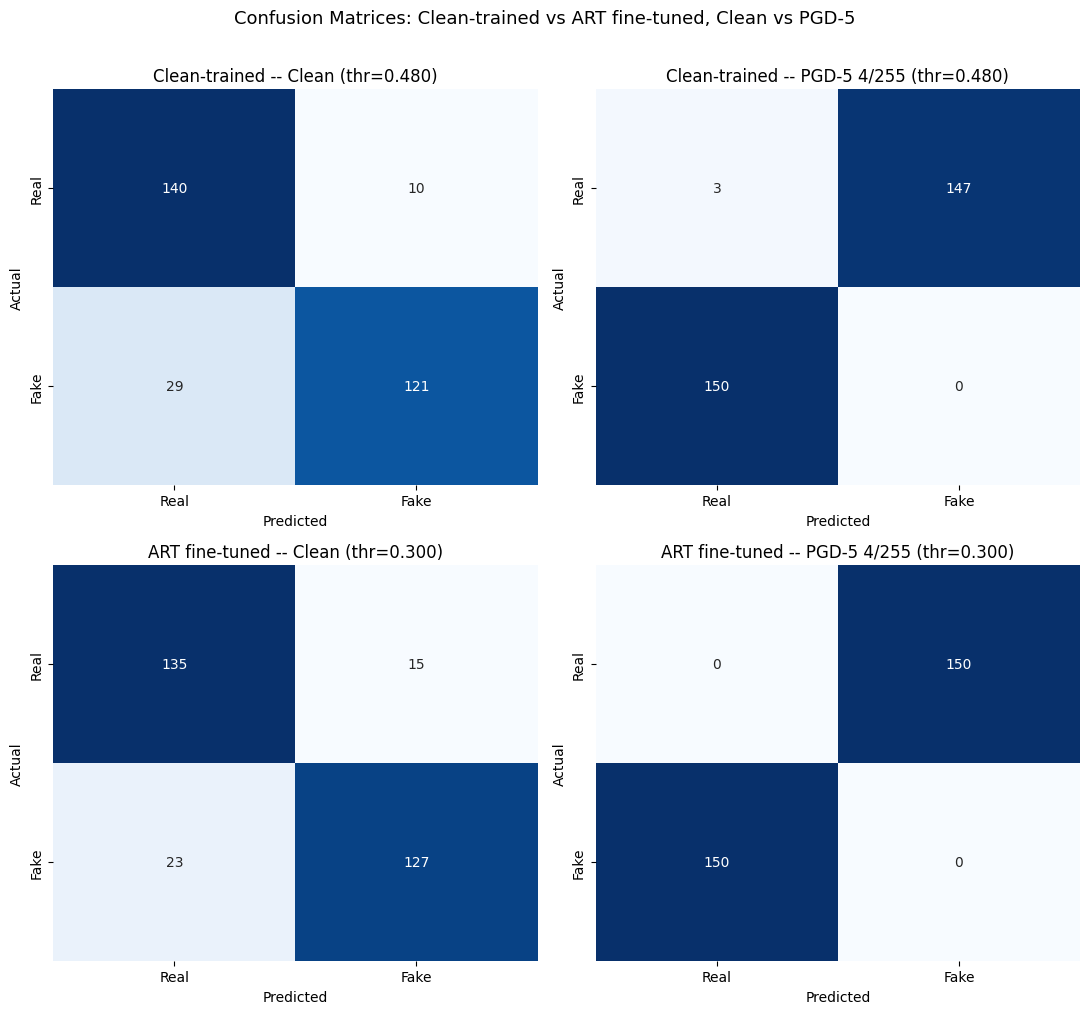

Confusion matrices generated for: Clean-trained/Clean, Clean-trained/PGD-5, ART fine-tuned/Clean, ART fine-tuned/PGD-5 (each at its own validation-selected threshold).


In [13]:
# ============================================================
# CELL: Confusion matrices (clean-trained & ART-trained, Clean & PGD-5)
# ============================================================
# Reuses the raw predictions cached in Cell 12 (no re-running of PGD-5,
# which is the most expensive attack evaluated). Each model uses its OWN
# validation-selected threshold, consistent with the rest of the notebook.

confusion_conditions = [
    ("Clean-trained", "Clean", clean_selected_threshold),
    ("Clean-trained", "PGD-5 4/255", clean_selected_threshold),
    ("ART fine-tuned", "Clean", art_selected_threshold),
    ("ART fine-tuned", "PGD-5 4/255", art_selected_threshold),
]

fig, axes = plt.subplots(2, 2, figsize=(11, 10))

for ax, (model_tag, condition, threshold) in zip(axes.flat, confusion_conditions):
    labels_, probs_ = raw_predictions_cache[(model_tag, condition)]
    preds_ = (probs_ >= threshold).astype(int)
    cm = confusion_matrix(labels_, preds_, labels=[0, 1])

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                xticklabels=['Real', 'Fake'], yticklabels=['Real', 'Fake'])
    ax.set_title(f"{model_tag} -- {condition} (thr={threshold:.3f})")
    ax.set_ylabel("Actual")
    ax.set_xlabel("Predicted")

plt.suptitle("Confusion Matrices: Clean-trained vs ART fine-tuned, Clean vs PGD-5", y=1.01, fontsize=13)
plt.tight_layout()
plt.savefig("/kaggle/working/confusion_matrices_4condition.png", dpi=150, bbox_inches="tight")
plt.show()

print("Confusion matrices generated for: Clean-trained/Clean, Clean-trained/PGD-5, "
      "ART fine-tuned/Clean, ART fine-tuned/PGD-5 (each at its own validation-selected threshold).")


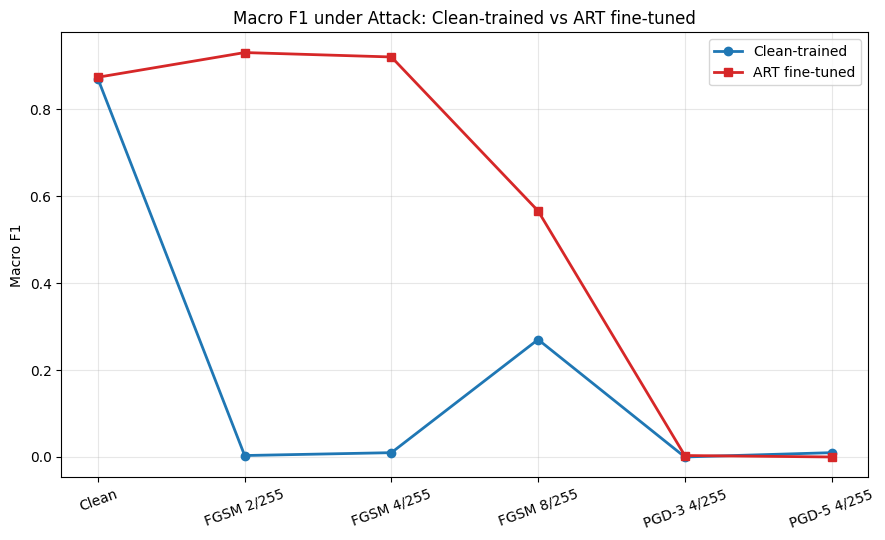

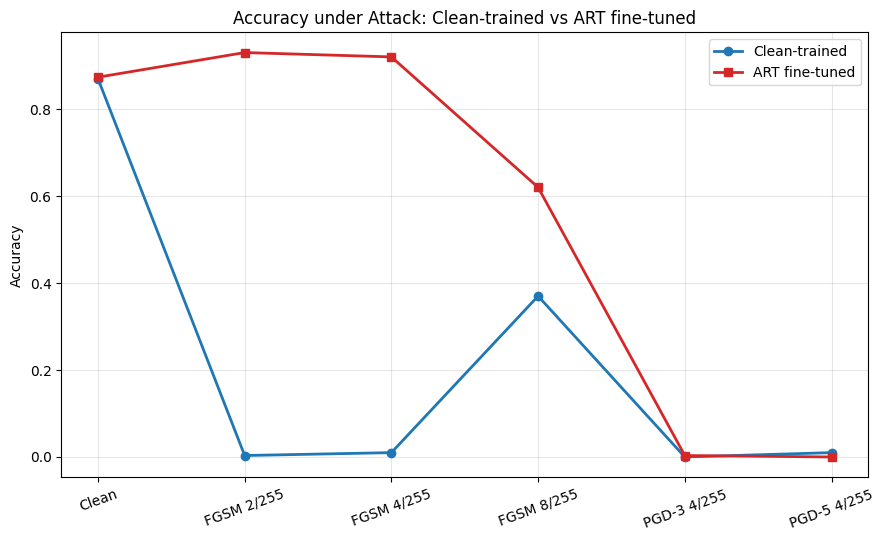

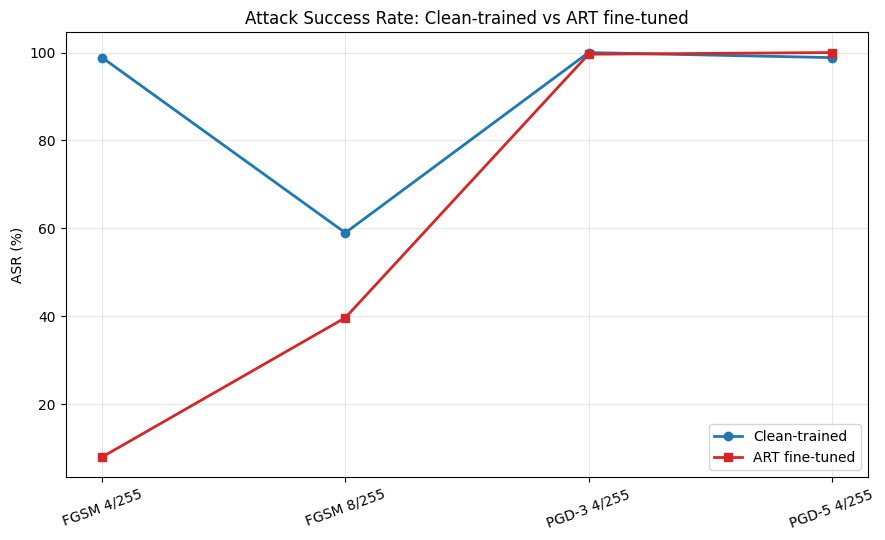

Saved robustness_macro_f1.png, robustness_accuracy.png, robustness_asr.png to /kaggle/working/


In [14]:
# ============================================================
# CELL: Robustness comparison plots
# ============================================================
# Built entirely from `comparison_df` (Cell 12) -- no hard-coded values.

attack_order = ["Clean", "FGSM 2/255", "FGSM 4/255", "FGSM 8/255", "PGD-3 4/255", "PGD-5 4/255"]
asr_order = ["FGSM 4/255", "FGSM 8/255", "PGD-3 4/255", "PGD-5 4/255"]

plot_df = comparison_df.copy()
plot_df["Condition"] = pd.Categorical(plot_df["Condition"], categories=attack_order, ordered=True)
plot_df = plot_df.sort_values(["Model", "Condition"])


def _plot_metric_vs_attack(metric_col, ylabel, title, out_path, conditions=attack_order):
    plt.figure(figsize=(9, 5.5))
    for model_name, marker, color in [("Clean-trained", "o", "tab:blue"), ("ART fine-tuned", "s", "tab:red")]:
        sub = plot_df[(plot_df["Model"] == model_name) & (plot_df["Condition"].isin(conditions))]
        sub = sub.set_index("Condition").reindex(conditions).reset_index()
        y = sub[metric_col] * (100 if metric_col == "asr" else 1)
        plt.plot(range(len(conditions)), y, marker=marker, label=model_name, color=color, linewidth=2)
    plt.xticks(range(len(conditions)), conditions, rotation=20)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(out_path, dpi=150)
    plt.show()


# Plot 1: Macro F1 under attacks
_plot_metric_vs_attack("f1", "Macro F1", "Macro F1 under Attack: Clean-trained vs ART fine-tuned",
                        "/kaggle/working/robustness_macro_f1.png")

# Plot 2: Accuracy under attacks
_plot_metric_vs_attack("accuracy", "Accuracy", "Accuracy under Attack: Clean-trained vs ART fine-tuned",
                        "/kaggle/working/robustness_accuracy.png")

# Plot 3: Attack Success Rate (ASR) -- attacked conditions only ("Clean" has no ASR)
_plot_metric_vs_attack("asr", "ASR (%)", "Attack Success Rate: Clean-trained vs ART fine-tuned",
                        "/kaggle/working/robustness_asr.png", conditions=asr_order)

print("Saved robustness_macro_f1.png, robustness_accuracy.png, robustness_asr.png to /kaggle/working/")


INTERPRETATION CAVEAT: Grad-CAM shows which spatial regions contributed to the
model's prediction. It does NOT by itself prove the exact manipulation artifact --
treat it as a localization aid, not ground-truth evidence of tampering.

Grad-CAM for test sample_idx=0:


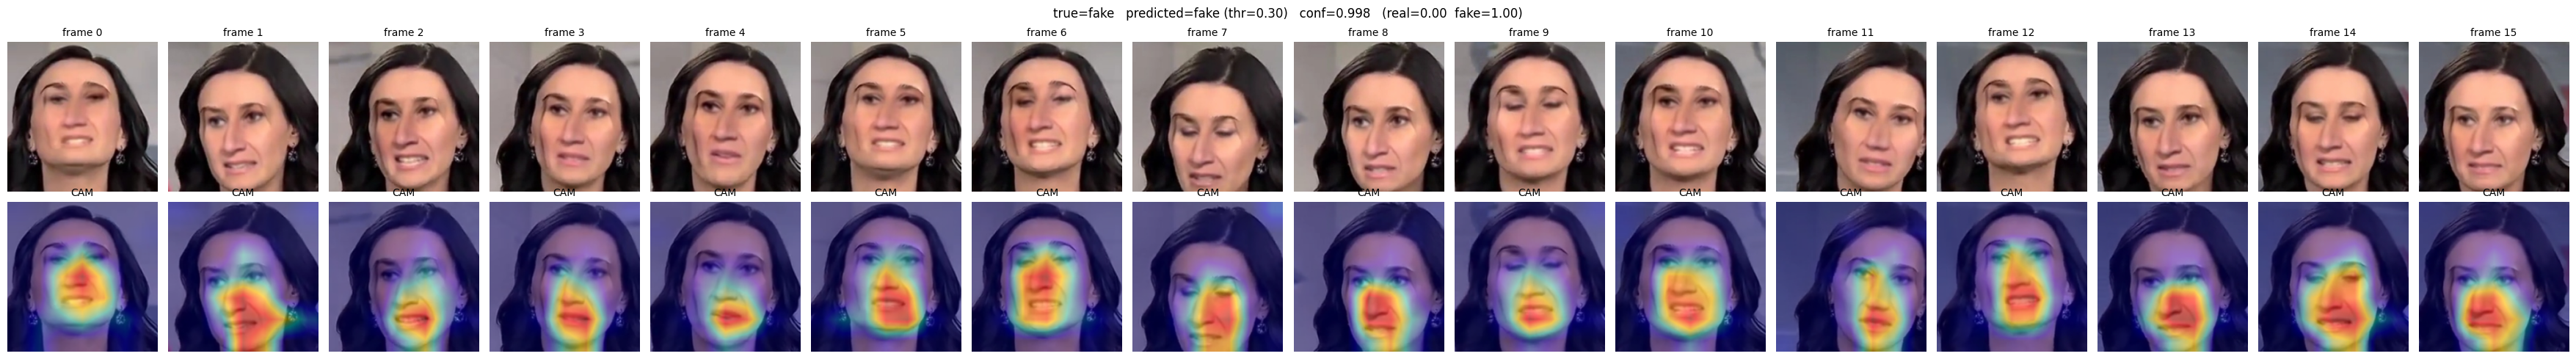


Grad-CAM for test sample_idx=5 (different sample, to confirm sample_idx is respected):


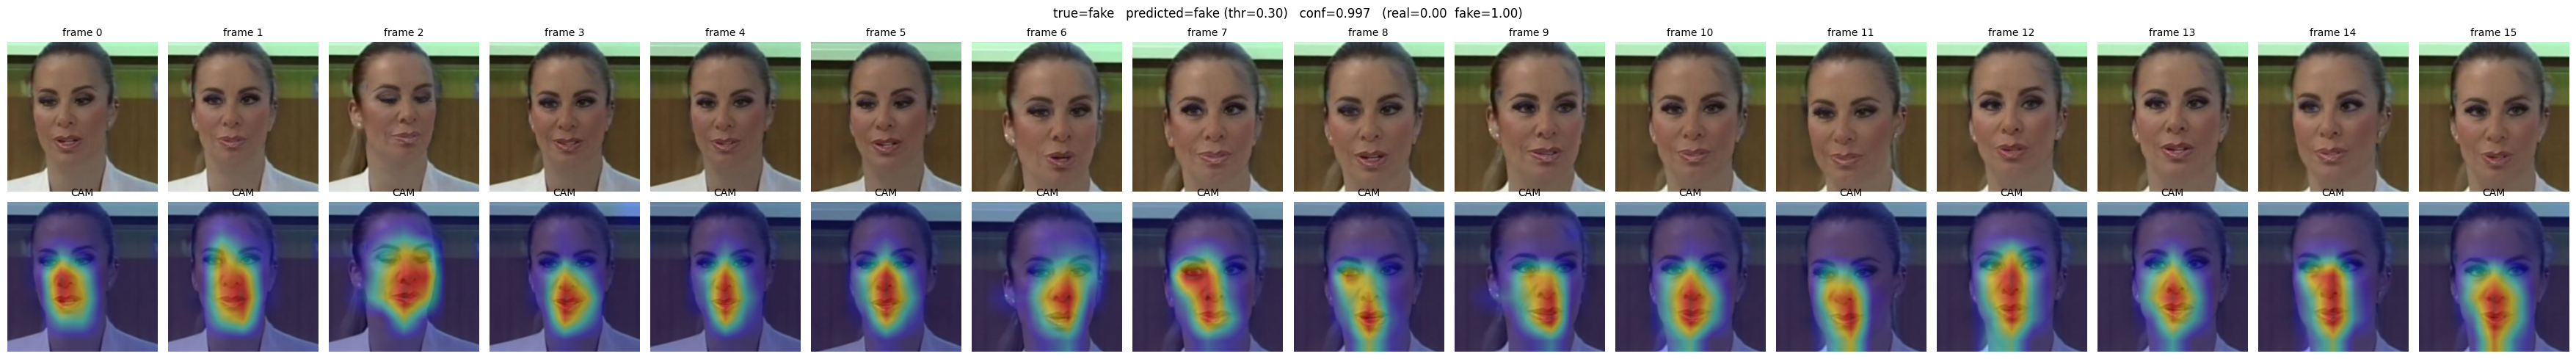

In [15]:
# ============================================================
# CELL 13: Grad-CAM
# ============================================================
# Same VideoGradCAM approach as the working notebook, using the
# `_prepare_model_for_attack` / `_restore_model_modes` helpers (Cell 9) so
# BatchNorm/Dropout stay frozen during the backward pass (deterministic,
# dropout-free CAMs) while the LSTM still gets cuDNN's training-mode
# backward kernel it requires. Target layer: the final EfficientNet-B1
# stage block. Generates a per-frame heatmap for all 16 sampled frames, and
# is run on two different `sample_idx` values to explicitly verify the
# function does not silently ignore the requested index.

class VideoGradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self.target_layer.register_forward_hook(self.save_activation)
        self.target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output.detach()

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate_heatmaps_all_frames(self, video_tensor):
        """video_tensor: [1, seq_len, 3, 224, 224]. Returns logits, fake
        probability, and per-frame heatmaps [seq_len, H, W]."""
        prev_modes = _prepare_model_for_attack(self.model)

        logits = self.model(video_tensor)
        prob = torch.sigmoid(logits).item()

        self.model.zero_grad()
        logits.backward()

        grads = self.gradients   # [seq_len, C, H, W]
        acts = self.activations  # [seq_len, C, H, W]

        weights = torch.mean(grads, dim=(2, 3), keepdim=True)
        cams = torch.sum(weights * acts, dim=1)
        cams = Fn.relu(cams)

        heatmaps = []
        for i in range(cams.size(0)):
            cam = cams[i]
            cam = cam - cam.min()
            cam = cam / (cam.max() + 1e-7)
            heatmaps.append(cam.cpu().numpy())

        _restore_model_modes(self.model, prev_modes)
        return logits, prob, np.array(heatmaps)


def visualize_gradcam_sequence(model, dataset, sample_idx=0, num_frames_to_display=None):
    if num_frames_to_display is None:
        num_frames_to_display = CONFIG["seq_len"]  # show Frame 1..16, per spec
    target_layer = model.feature_extractor[0][-1]
    grad_cam = VideoGradCAM(model, target_layer)

    video_tensor, true_label_idx = dataset[sample_idx]
    true_label = "fake" if int(true_label_idx.item()) == 1 else "real"

    video_tensor_input = video_tensor.unsqueeze(0).to(CONFIG["device"])
    video_tensor_input.requires_grad = True

    _, fake_prob, heatmaps = grad_cam.generate_heatmaps_all_frames(video_tensor_input)

    real_prob = 1.0 - fake_prob
    pred_label = "fake" if fake_prob >= art_selected_threshold else "real"
    conf = fake_prob if pred_label == "fake" else real_prob

    total_seq_len = video_tensor.size(0)
    frame_indices = np.linspace(0, total_seq_len - 1, num_frames_to_display, dtype=int)

    mean = np.array(IMAGENET_MEAN)
    std = np.array(IMAGENET_STD)

    fig, axes = plt.subplots(2, num_frames_to_display, figsize=(2.2 * num_frames_to_display, 5))
    fig.suptitle(
        f"true={true_label}   predicted={pred_label} (thr={art_selected_threshold:.2f})   "
        f"conf={conf:.3f}   (real={real_prob:.2f}  fake={fake_prob:.2f})",
        fontsize=12, y=0.98
    )

    for i, f_idx in enumerate(frame_indices):
        src_frame = video_tensor[f_idx].detach().cpu().numpy().transpose(1, 2, 0)
        src_frame = std * src_frame + mean
        src_frame = np.clip(src_frame, 0, 1)
        src_frame_uint8 = (src_frame * 255).astype(np.uint8)

        heatmap_resized = cv2.resize(heatmaps[f_idx], (CONFIG["img_size"], CONFIG["img_size"]))
        heatmap_color = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
        heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)

        overlay = cv2.addWeighted(src_frame_uint8, 0.6, heatmap_color, 0.4, 0)

        axes[0, i].imshow(src_frame)
        axes[0, i].set_title(f"frame {f_idx}", fontsize=10)
        axes[0, i].axis('off')

        axes[1, i].imshow(overlay)
        axes[1, i].set_title("CAM", fontsize=10)
        axes[1, i].axis('off')

    plt.tight_layout()
    plt.savefig("/kaggle/working/gradcam_visualization.png", dpi=150)
    plt.show()


print("INTERPRETATION CAVEAT: Grad-CAM shows which spatial regions contributed to the")
print("model's prediction. It does NOT by itself prove the exact manipulation artifact --")
print("treat it as a localization aid, not ground-truth evidence of tampering.\n")

# art_model already holds the best ART checkpoint (loaded in Cell 12).
# Two different sample_idx values are shown explicitly to verify the function
# genuinely uses the requested index (rather than silently defaulting to one sample).
print("Grad-CAM for test sample_idx=0:")
visualize_gradcam_sequence(art_model, test_dataset, sample_idx=0)

print("\nGrad-CAM for test sample_idx=5 (different sample, to confirm sample_idx is respected):")
visualize_gradcam_sequence(art_model, test_dataset, sample_idx=5)


In [16]:
# ============================================================
# CELL 14: Ablation study
# ============================================================
# The imbalance-handling ablation (A/B/C) always runs -- it directly
# validates the WeightedRandomSampler default used in Cell 5. The
# architecture ablations (LSTM layers, pooling, frame count) are each
# gated behind their own CONFIG flag (default False) since every one of
# them trains an additional lightweight model and Kaggle runtime is
# limited. None of this changes the MAIN model trained in Cells 5/11.

def run_lightweight_variant(tag, epochs, num_layers=None, use_attention=None,
                             seq_len=None, use_sampler=None, custom_pos_weight=None):
    set_global_seed(CONFIG["seed"])

    variant_model = build_model(num_layers=num_layers, use_attention=use_attention)

    if seq_len is not None and seq_len != CONFIG["seq_len"]:
        v_train_dataset = PreextractedVideoDataset(train_records, seq_len=seq_len,
                                                     img_size=CONFIG["img_size"], is_train=True)
        v_val_dataset = PreextractedVideoDataset(val_records, seq_len=seq_len,
                                                   img_size=CONFIG["img_size"], is_train=False)
    else:
        v_train_dataset, v_val_dataset = train_dataset, val_dataset

    use_sampler = CONFIG["use_weighted_sampler"] if use_sampler is None else use_sampler
    if use_sampler:
        v_sampler = WeightedRandomSampler(weights=torch.as_tensor(sample_weights, dtype=torch.double),
                                           num_samples=len(sample_weights), replacement=True)
        v_train_loader = DataLoader(v_train_dataset, batch_size=CONFIG["batch_size"], sampler=v_sampler,
                                     num_workers=CONFIG["num_workers"], drop_last=True)
    else:
        v_train_loader = DataLoader(v_train_dataset, batch_size=CONFIG["batch_size"], shuffle=True,
                                     num_workers=CONFIG["num_workers"], drop_last=True)
    v_val_loader = DataLoader(v_val_dataset, batch_size=CONFIG["batch_size"], shuffle=False,
                               num_workers=CONFIG["num_workers"])

    v_criterion = nn.BCEWithLogitsLoss(pos_weight=custom_pos_weight)
    optimizer = build_optimizer(variant_model)
    scaler = torch.amp.GradScaler("cuda") if USE_AMP else None

    for _ in range(epochs):
        train_epoch(variant_model, v_train_loader, optimizer, v_criterion, scaler, USE_AMP,
                    adversarial=False, grad_clip_norm=CONFIG["grad_clip_norm"])

    val_metrics = validate_epoch(variant_model, v_val_loader, v_criterion, threshold=0.5, use_amp=USE_AMP)

    del variant_model, optimizer, scaler
    if seq_len is not None and seq_len != CONFIG["seq_len"]:
        del v_train_dataset, v_val_dataset
    free_cuda_memory()

    return {"Experiment": tag, "Val Accuracy": val_metrics["accuracy"],
            "Val Precision": val_metrics["precision"], "Val Recall": val_metrics["recall"],
            "Val Macro F1": val_metrics["f1"], "Val Balanced Accuracy": val_metrics["balanced_accuracy"],
            "Val ROC-AUC": val_metrics["roc_auc"], "Val PR-AUC": val_metrics["pr_auc"]}


# ---- Imbalance-handling ablation (always runs) ----
print("=" * 60)
print("IMBALANCE-HANDLING ABLATION (Experiments A/B/C)")
print("=" * 60)

full_pos_weight = torch.tensor([n_neg / max(n_pos, 1)], device=CONFIG["device"])
mild_pos_weight = torch.tensor([float(np.sqrt(n_neg / max(n_pos, 1)))], device=CONFIG["device"])

exp_A = run_lightweight_variant("A: class-weight only, no sampler", CONFIG["ablation_epochs"],
                                 use_sampler=False, custom_pos_weight=full_pos_weight)
exp_B = run_lightweight_variant("B: WeightedRandomSampler + plain BCE (Cell 5 default)",
                                 CONFIG["ablation_epochs"], use_sampler=True, custom_pos_weight=None)
exp_C = run_lightweight_variant("C: WeightedRandomSampler + mild class-weight",
                                 CONFIG["ablation_epochs"], use_sampler=True, custom_pos_weight=mild_pos_weight)

imbalance_ablation_df = pd.DataFrame([exp_A, exp_B, exp_C])
print(imbalance_ablation_df.to_string(index=False))

best_imbalance_row = imbalance_ablation_df.loc[imbalance_ablation_df["Val Macro F1"].idxmax()]
print(f"\nBest imbalance-handling approach by validation macro F1: {best_imbalance_row['Experiment']}")
print("(Cell 5 used Experiment B by default. If a different experiment scored meaningfully "
      "higher here, re-run Cell 5 with that configuration before finalizing the model.)")

# ---- Architecture ablations (each individually gated) ----
architecture_ablation_rows = []

if CONFIG["run_ablation_lstm_layers"]:
    print("\nRunning LSTM-layers ablation...")
    architecture_ablation_rows.append(
        run_lightweight_variant("1-layer LSTM", CONFIG["ablation_epochs"], num_layers=1))
    architecture_ablation_rows.append(
        run_lightweight_variant("2-layer LSTM (main model)", CONFIG["ablation_epochs"], num_layers=2))
else:
    print("\nSkipping LSTM-layers ablation (CONFIG['run_ablation_lstm_layers']=False).")

if CONFIG["run_ablation_pooling"]:
    print("Running pooling ablation...")
    architecture_ablation_rows.append(
        run_lightweight_variant("Mean pooling (main model)", CONFIG["ablation_epochs"], use_attention=False))
    architecture_ablation_rows.append(
        run_lightweight_variant("Attention pooling", CONFIG["ablation_epochs"], use_attention=True))
else:
    print("Skipping pooling ablation (CONFIG['run_ablation_pooling']=False).")

if CONFIG["run_ablation_frames"]:
    print("Running frame-count ablation...")
    architecture_ablation_rows.append(run_lightweight_variant("8 frames", CONFIG["ablation_epochs"], seq_len=8))
    architecture_ablation_rows.append(
        run_lightweight_variant("16 frames (main model)", CONFIG["ablation_epochs"], seq_len=16))
    architecture_ablation_rows.append(run_lightweight_variant("24 frames", CONFIG["ablation_epochs"], seq_len=24))
else:
    print("Skipping frame-count ablation (CONFIG['run_ablation_frames']=False).")

if architecture_ablation_rows:
    architecture_ablation_df = pd.DataFrame(architecture_ablation_rows)
    print("\nArchitecture/frame-count ablation results:")
    print(architecture_ablation_df.to_string(index=False))
else:
    architecture_ablation_df = pd.DataFrame(columns=[
        "Experiment", "Val Accuracy", "Val Precision", "Val Recall",
        "Val Macro F1", "Val Balanced Accuracy", "Val ROC-AUC", "Val PR-AUC",
    ])
    print("\nNo architecture ablations were run this session (all gated flags are False). "
          "The main model (2-layer unidirectional LSTM, mean pooling, 16 frames) is used as-is.")


IMBALANCE-HANDLING ABLATION (Experiments A/B/C)


                                           Experiment  Val Accuracy  Val Precision  Val Recall  Val Macro F1  Val Balanced Accuracy  Val ROC-AUC  Val PR-AUC
                     A: class-weight only, no sampler      0.500000       0.250000    0.500000      0.333333               0.500000     0.506222    0.504536
B: WeightedRandomSampler + plain BCE (Cell 5 default)      0.523333       0.559585    0.523333      0.437827               0.523333     0.542533    0.533615
         C: WeightedRandomSampler + mild class-weight      0.530000       0.626428    0.530000      0.419267               0.530000     0.548778    0.541466

Best imbalance-handling approach by validation macro F1: B: WeightedRandomSampler + plain BCE (Cell 5 default)
(Cell 5 used Experiment B by default. If a different experiment scored meaningfully higher here, re-run Cell 5 with that configuration before finalizing the model.)

Skipping LSTM-layers ablation (CONFIG['run_ablation_lstm_layers']=False).
Skipping pooling abl

In [17]:
# ============================================================
# CELL 15: Final comparison table
# ============================================================
# Publication-style table, built programmatically from `comparison_df`
# (Cell 12) -- nothing here is typed in by hand. Columns match the
# requested format exactly: Model | Condition | Accuracy | Precision |
# Recall | Macro F1 | Balanced Accuracy | ROC-AUC | PR-AUC |
# F1 Retention (%) | F1 Drop | ASR (%)

PUBLICATION_CONDITIONS = ["Clean", "FGSM 4/255", "FGSM 8/255", "PGD-3 4/255", "PGD-5 4/255"]

publication_table = comparison_df[comparison_df["Condition"].isin(PUBLICATION_CONDITIONS)].copy()
publication_table["Condition"] = pd.Categorical(
    publication_table["Condition"], categories=PUBLICATION_CONDITIONS, ordered=True
)
publication_table = publication_table.sort_values(["Model", "Condition"]).reset_index(drop=True)

publication_table = publication_table.rename(columns={
    "accuracy": "Accuracy", "precision": "Precision", "recall": "Recall", "f1": "Macro F1",
    "balanced_accuracy": "Balanced Accuracy", "roc_auc": "ROC-AUC", "pr_auc": "PR-AUC",
    "F1 Retention %": "F1 Retention (%)",
})
publication_table["ASR (%)"] = publication_table["asr"].apply(
    lambda x: "N/A" if pd.isna(x) else f"{x * 100:.2f}"
)

publication_table = publication_table[[
    "Model", "Condition", "Accuracy", "Precision", "Recall", "Macro F1", "Balanced Accuracy",
    "ROC-AUC", "PR-AUC", "F1 Retention (%)", "F1 Drop", "ASR (%)",
]]

print("=" * 130)
print("FINAL ADVERSARIAL ROBUSTNESS TABLE (test set, each model at its own validation-selected threshold)")
print("=" * 130)
print(publication_table.to_string(index=False))

print(f"\nSelected classification thresholds -- Clean-trained: {clean_selected_threshold:.3f}  |  "
      f"ART fine-tuned: {art_selected_threshold:.3f}  (both chosen on VALIDATION data only, see Cells 8/12)")

if len(architecture_ablation_df) > 0:
    print("\n(Architecture ablation results -- VALIDATION set, lightweight runs, for reference only:)")
    print(architecture_ablation_df.to_string(index=False))
print("\n(Imbalance-handling ablation -- VALIDATION set:)")
print(imbalance_ablation_df.to_string(index=False))


# ---- Persist run artifacts ----
def _json_safe(v):
    if isinstance(v, torch.device):
        return str(v)
    return v


run_summary = {
    "config": {k: _json_safe(v) for k, v in CONFIG.items()},
    "clean_best_val_f1": clean_best_val_f1,
    "art_best_val_f1": art_best_val_f1,
    "clean_selected_threshold": clean_selected_threshold,
    "art_selected_threshold": art_selected_threshold,
    "publication_table": publication_table.to_dict(orient="records"),
    "full_robustness_comparison": comparison_df.to_dict(orient="records"),
    "imbalance_ablation": imbalance_ablation_df.to_dict(orient="records"),
    "architecture_ablation": architecture_ablation_df.to_dict(orient="records"),
    "confidence_degradation": confidence_df.to_dict(orient="records"),
}
with open(CONFIG["save_best_metrics_path"], "w") as f:
    json.dump(run_summary, f, indent=2, default=str)
with open(CONFIG["save_run_config_path"], "w") as f:
    json.dump({k: _json_safe(v) for k, v in CONFIG.items()}, f, indent=2, default=str)
print(f"\nSaved final metrics to {CONFIG['save_best_metrics_path']}")
print(f"Saved run configuration to {CONFIG['save_run_config_path']}")


FINAL ADVERSARIAL ROBUSTNESS TABLE (test set, each model at its own validation-selected threshold)
         Model   Condition  Accuracy  Precision   Recall  Macro F1  Balanced Accuracy  ROC-AUC   PR-AUC  F1 Retention (%)   F1 Drop ASR (%)
ART fine-tuned       Clean  0.873333   0.874398 0.873333  0.873243           0.873333 0.936022 0.937095        100.000000  0.000000     N/A
ART fine-tuned  FGSM 4/255  0.920000   0.923691 0.920000  0.919825           0.920000 0.982289 0.983866        105.334391 -0.046582    8.02
ART fine-tuned  FGSM 8/255  0.620000   0.739702 0.620000  0.565791           0.620000 0.868978 0.884953         64.791971  0.307452   39.69
ART fine-tuned PGD-3 4/255  0.003333   0.003311 0.003333  0.003322           0.003333 0.000000 0.308856          0.380451  0.869921   99.62
ART fine-tuned PGD-5 4/255  0.000000   0.000000 0.000000  0.000000           0.000000 0.000000 0.309098          0.000000  0.873243  100.00
 Clean-trained       Clean  0.870000   0.876033 0.870000  0.8